# ViT-B/16 — Vision Transformer (ImageNet-21k)

**EEEM068 Applied Machine Learning — University of Surrey**

Architecture experiment using **ViT-B/16 pre-trained on ImageNet-21k** (supervised, via `timm`).  
Compared against the EfficientNet-B0 baseline under identical training conditions.

| Setting | Value |
|---|---|
| Architecture | ViT-B/16 (`vit_base_patch16_224.augreg_in21k_ft_in1k`) |
| Pre-training | ImageNet-21k supervised → fine-tuned on ImageNet-1k |
| Loss | CrossEntropyLoss (no class weights) |
| Sampler | Standard shuffle |
| Augmentation | Resize → RandomCrop → HFlip → Normalise |
| Normalisation | mean=(0.5, 0.5, 0.5), std=(0.5, 0.5, 0.5) |
| Optimiser | AdamW, lr=3e-4, weight_decay=1e-2 |
| Scheduler | CosineAnnealingLR |
| Metric | Quadratic Weighted Kappa (QWK) |

## 1. Imports

In [ ]:
import os
os.environ['PYTORCH_CUDA_ALLOC_CONF'] = 'expandable_segments:True'

import random
from pathlib import Path

import timm
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.ticker as ticker
from PIL import Image
from tqdm.auto import tqdm

import torch
import torch.nn as nn
from torch.utils.data import Dataset, DataLoader
from torchvision import transforms
from sklearn.metrics import (
    classification_report, cohen_kappa_score, confusion_matrix
)
from sklearn.metrics import f1_score, accuracy_score

print(f'PyTorch : {torch.__version__}')
print(f'timm    : {timm.__version__}')
print(f'CUDA    : {torch.cuda.is_available()}')
# torch.cuda.empty_cache()
# torch.cuda.reset_peak_memory_stats()

PyTorch : 2.11.0+cu130
timm    : 1.0.26
CUDA    : True


## 2. Configuration

In [57]:
# ── Paths ─────────────────────────────────────────────────────
NOTEBOOK_DIR    = Path().resolve()
ROOT            = NOTEBOOK_DIR.parent

DATA_ROOT       = ROOT / 'data' / 'diabetic-retinopathy-detection'
TRAIN_DIR       = DATA_ROOT / 'train_proc'        # 13-stage preprocessed images
VAL_DIR         = DATA_ROOT / 'val_proc'
TEST_LABELS_DIR = DATA_ROOT / 'test_labels_proc'
TRAIN_CSV       = DATA_ROOT / 'train_split.csv'
VAL_CSV         = DATA_ROOT / 'val_split.csv'
TEST_CSV        = DATA_ROOT / 'test_split.csv'

OUT_DIR     = ROOT / 'outputs' / 'vit_b16'
CKPT_DIR    = OUT_DIR / 'checkpoints'
FIGURES_DIR = OUT_DIR / 'figures'
for d in (OUT_DIR, CKPT_DIR, FIGURES_DIR):
    d.mkdir(parents=True, exist_ok=True)

# ── Experiment ────────────────────────────────────────────────
EXPERIMENT_NAME = 'vit_b16'
MODEL_NAME      = 'vit_base_patch16_224.augreg_in21k_ft_in1k'

# ── Reproducibility ───────────────────────────────────────────
SEED = 42

# ── Data ──────────────────────────────────────────────────────
IMAGE_SIZE  = 224
NUM_CLASSES = 5
CLASS_NAMES = ['No DR', 'Mild', 'Moderate', 'Severe', 'Proliferative']

# ViT-B/16 (IN21k) uses symmetric normalisation, not ImageNet RGB stats
VIT_MEAN = (0.5, 0.5, 0.5)
VIT_STD  = (0.5, 0.5, 0.5)

# ── Training ──────────────────────────────────────────────────
BATCH_SIZE               = 16
NUM_WORKERS              = 4
EPOCHS                   = 25
LR                       = 1e-4
WEIGHT_DECAY             = 1e-2
EARLY_STOPPING_PATIENCE  = 5

# Best Hyperparameters suggested by hyperparameter tuning experiment 4
# LR=3e-05  
# BATCH_SIZE=16  
# WEIGHT_DECAY=1e-03
# NUM_WORKERS=4
# EPOCHS=25
# EARLY_STOPPING_PATIENCE=5

print('Config set. Root:', ROOT)
print(f'Images: {TRAIN_DIR.name} / {VAL_DIR.name} / {TEST_LABELS_DIR.name}')

Config set. Root: /scratch/AML_G14_CW
Images: train_proc / val_proc / test_labels_proc


In [58]:

# ── Seed + device ─────────────────────────────────────────────
def set_seed(seed: int) -> None:
    random.seed(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)
    if torch.cuda.is_available():
        torch.cuda.manual_seed_all(seed)

set_seed(SEED)
device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
print('Device:', device)

Device: cuda


In [59]:
# ── Checkpoint paths — defined once here, reused by every eval cell ──────────
# Running this cell is sufficient to resume evaluation after a kernel restart.
CKPT_BASELINE = CKPT_DIR / f'{EXPERIMENT_NAME}_best.pt'
CKPT_EXP1     = ROOT / 'outputs' / 'vit_b16_exp1' / 'checkpoints' / 'vit_b16_exp1_best.pt'
CKPT_EXP2     = ROOT / 'outputs' / 'vit_b16_exp2' / 'checkpoints' / 'vit_b16_exp2_best.pt'
CKPT_EXP3_P1  = ROOT / 'outputs' / 'vit_b16_exp3' / 'checkpoints' / 'vit_b16_exp3_phase1_best.pt'
CKPT_EXP3     = ROOT / 'outputs' / 'vit_b16_exp3' / 'checkpoints' / 'vit_b16_exp3_best.pt'
CKPT_EXP5     = ROOT / 'outputs' / 'vit_b16_exp5' / 'checkpoints' / 'vit_b16_exp5_best.pt'
CKPT_EXP6_P1  = ROOT / 'outputs' / 'vit_b16_exp6' / 'checkpoints' / 'vit_b16_exp6_phase1_best.pt'
CKPT_EXP6     = ROOT / 'outputs' / 'vit_b16_exp6' / 'checkpoints' / 'vit_b16_exp6_best.pt'
CKPT_EXP8_P1  = ROOT / 'outputs' / 'vit_b16_exp8' / 'checkpoints' / 'vit_b16_exp8_phase1_best.pt'
CKPT_EXP8     = ROOT / 'outputs' / 'vit_b16_exp8' / 'checkpoints' / 'vit_b16_exp8_best.pt'

print('Checkpoint registry:')
for label, path in [
    ('Baseline',  CKPT_BASELINE),
    ('Exp1',      CKPT_EXP1),
    ('Exp2',      CKPT_EXP2),
    ('Exp3 P1',   CKPT_EXP3_P1),
    ('Exp3',      CKPT_EXP3),
    ('Exp5',      CKPT_EXP5),
    ('Exp6 P1',   CKPT_EXP6_P1),
    ('Exp6',      CKPT_EXP6),
    ('Exp8 P1',   CKPT_EXP8_P1),
    ('Exp8',      CKPT_EXP8),
]:
    status = 'saved' if path.exists() else 'not yet trained'
    print(f'  {label:<12}: {path.relative_to(ROOT)}  [{status}]')


Checkpoint registry:
  Baseline    : outputs/vit_b16/checkpoints/vit_b16_best.pt  [saved]
  Exp1        : outputs/vit_b16_exp1/checkpoints/vit_b16_exp1_best.pt  [saved]
  Exp2        : outputs/vit_b16_exp2/checkpoints/vit_b16_exp2_best.pt  [saved]
  Exp3 P1     : outputs/vit_b16_exp3/checkpoints/vit_b16_exp3_phase1_best.pt  [saved]
  Exp3        : outputs/vit_b16_exp3/checkpoints/vit_b16_exp3_best.pt  [saved]
  Exp5        : outputs/vit_b16_exp5/checkpoints/vit_b16_exp5_best.pt  [saved]
  Exp6 P1     : outputs/vit_b16_exp6/checkpoints/vit_b16_exp6_phase1_best.pt  [not yet trained]
  Exp6        : outputs/vit_b16_exp6/checkpoints/vit_b16_exp6_best.pt  [not yet trained]


## 3. Load Pre-Split Data

In [60]:
train_df = pd.read_csv(TRAIN_CSV)
val_df   = pd.read_csv(VAL_CSV)
test_df  = pd.read_csv(TEST_CSV)

print(f'Train : {len(train_df):,} images  (dir: train/)')
print(f'Val   : {len(val_df):,} images   (dir: val/)')
print(f'Test  : {len(test_df):,} images   (dir: test_labels/)')
print()
print(f'{"Grade":<6} {"Name":<18} {"Train":>7} {"Val":>7} {"Test":>7}')
print('-' * 52)
for g, name in enumerate(CLASS_NAMES):
    t = (train_df['level'] == g).sum()
    v = (val_df['level']   == g).sum()
    s = (test_df['level']  == g).sum()
    print(f'  {g}    {name:<18} {t:>6,}  {v:>6,}  {s:>6,}')

Train : 24,588 images  (dir: train/)
Val   : 5,269 images   (dir: val/)
Test  : 5,269 images   (dir: test_labels/)

Grade  Name                 Train     Val    Test
----------------------------------------------------
  0    No DR              18,067   3,871   3,872
  1    Mild                1,710     367     366
  2    Moderate            3,704     794     794
  3    Severe                611     131     131
  4    Proliferative         496     106     106


## 4. Dataset and DataLoaders

In [61]:
class DRDataset(Dataset):
    """Fundus image dataset. Reads images from data_dir using the 'image' column."""

    def __init__(self, df: pd.DataFrame, data_dir: Path, transform=None):
        self.df        = df.reset_index(drop=True)
        self.data_dir  = Path(data_dir)
        self.transform = transform

    def __len__(self) -> int:
        return len(self.df)

    def __getitem__(self, idx: int):
        row   = self.df.iloc[idx]
        image = Image.open(self.data_dir / f"{row['image']}.jpeg").convert('RGB')
        label = int(row['level'])
        if self.transform is not None:
            image = self.transform(image)
        return image, label


# ViT requires symmetric normalisation (0.5, 0.5, 0.5) — different from EfficientNet
train_transform = transforms.Compose([
    transforms.Resize(int(IMAGE_SIZE * 1.14)),
    transforms.RandomCrop(IMAGE_SIZE),
    transforms.RandomHorizontalFlip(p=0.5),
    transforms.ToTensor(),
    transforms.Normalize(VIT_MEAN, VIT_STD),
])

val_transform = transforms.Compose([
    transforms.Resize(IMAGE_SIZE),
    transforms.CenterCrop(IMAGE_SIZE),
    transforms.ToTensor(),
    transforms.Normalize(VIT_MEAN, VIT_STD),
])

train_ds = DRDataset(train_df, TRAIN_DIR,       transform=train_transform)
val_ds   = DRDataset(val_df,   VAL_DIR,         transform=val_transform)
test_ds  = DRDataset(test_df,  TEST_LABELS_DIR, transform=val_transform)

train_loader = DataLoader(
    train_ds, batch_size=BATCH_SIZE, shuffle=True,
    num_workers=NUM_WORKERS, pin_memory=True, drop_last=True,
    persistent_workers=NUM_WORKERS > 0,
)
val_loader = DataLoader(
    val_ds, batch_size=BATCH_SIZE, shuffle=False,
    num_workers=NUM_WORKERS, pin_memory=True,
    persistent_workers=NUM_WORKERS > 0,
)
test_loader = DataLoader(
    test_ds, batch_size=BATCH_SIZE, shuffle=False,
    num_workers=NUM_WORKERS, pin_memory=True,
    persistent_workers=NUM_WORKERS > 0,
)

print(f'Train loader: {len(train_loader)} batches/epoch')
print(f'Val loader  : {len(val_loader)} batches/epoch')
print(f'Test loader : {len(test_loader)} batches/epoch')

Train loader: 1536 batches/epoch
Val loader  : 330 batches/epoch
Test loader : 330 batches/epoch


## 5. Model

`vit_base_patch16_224.augreg_in21k_ft_in1k` — pre-trained on ImageNet-21k (21,843 classes),  
then fine-tuned on ImageNet-1k. The 1000-class head is replaced with a 5-class linear layer.

In [62]:
model = timm.create_model(
    MODEL_NAME,
    pretrained=True,
    num_classes=NUM_CLASSES,   # replaces the 1000-class head directly
)
model = model.to(device)

total_params = sum(p.numel() for p in model.parameters())
trainable    = sum(p.numel() for p in model.parameters() if p.requires_grad)
print(f'Model           : {MODEL_NAME}')
print(f'Total params    : {total_params:,}')
print(f'Trainable params: {trainable:,}')
print(f'Classifier head : {model.head}')

Model           : vit_base_patch16_224.augreg_in21k_ft_in1k
Total params    : 85,802,501
Trainable params: 85,802,501
Classifier head : Linear(in_features=768, out_features=5, bias=True)


## 6. Loss, Optimiser, Scheduler

Identical to the baseline — no class weights, standard AdamW + cosine schedule.

In [63]:
criterion = nn.CrossEntropyLoss()   # no class weights — matching baseline conditions
optimizer = torch.optim.AdamW(model.parameters(), lr=LR, weight_decay=WEIGHT_DECAY)
scheduler = torch.optim.lr_scheduler.CosineAnnealingLR(optimizer, T_max=EPOCHS)

print('Loss      :', criterion)
print('Optimiser :', optimizer.__class__.__name__, f'lr={LR}')
print('Scheduler :', scheduler.__class__.__name__)

Loss      : CrossEntropyLoss()
Optimiser : AdamW lr=0.0001
Scheduler : CosineAnnealingLR


## 7. Training Loop

In [64]:
use_amp = device.type == 'cuda'
scaler  = torch.amp.GradScaler('cuda', enabled=use_amp)


def run_epoch(loader, train_mode: bool):
    model.train(train_mode)
    total_loss, total = 0.0, 0
    all_preds, all_labels = [], []

    for images, labels in tqdm(loader, leave=False, desc='train' if train_mode else 'val'):
        images = images.to(device, non_blocking=True)
        labels = labels.to(device, non_blocking=True)

        with torch.autocast(device_type='cuda', enabled=use_amp):
            logits = model(images)
            loss   = criterion(logits, labels)

        if train_mode:
            optimizer.zero_grad(set_to_none=True)
            scaler.scale(loss).backward()
            scaler.step(optimizer)
            scaler.update()

        total_loss += loss.item() * labels.size(0)
        total      += labels.size(0)
        all_preds.extend(logits.argmax(dim=1).cpu().tolist())
        all_labels.extend(labels.cpu().tolist())

    return total_loss / total, all_labels, all_preds


print('run_epoch defined.')

run_epoch defined.


In [11]:
best_path     = CKPT_DIR / f'{EXPERIMENT_NAME}_best.pt'
best_val_loss = float('inf')
patience_left = EARLY_STOPPING_PATIENCE

history = {'train_loss': [], 'val_loss': [], 'train_acc': [], 'val_acc': []}

print(f"{'Epoch':<8} {'Tr Loss':>10} {'Tr Acc':>8} {'Val Loss':>10} {'Val Acc':>8}")
print('─' * 50)

for epoch in range(1, EPOCHS + 1):
    tr_loss, tr_labels, tr_preds = run_epoch(train_loader, train_mode=True)
    vl_loss, vl_labels, vl_preds = run_epoch(val_loader,   train_mode=False)
    scheduler.step()

    tr_acc = accuracy_score(tr_labels, tr_preds)
    vl_acc = accuracy_score(vl_labels, vl_preds)

    history['train_loss'].append(tr_loss)
    history['val_loss'].append(vl_loss)
    history['train_acc'].append(tr_acc)
    history['val_acc'].append(vl_acc)

    marker = ''
    if vl_loss < best_val_loss:
        best_val_loss = vl_loss
        patience_left = EARLY_STOPPING_PATIENCE
        torch.save({'epoch': epoch, 'model_state': model.state_dict(),
                    'val_loss': vl_loss}, best_path)
        marker = '  ← best'
    else:
        patience_left -= 1

    print(f'{epoch:<8} {tr_loss:>10.4f} {tr_acc:>8.4f} {vl_loss:>10.4f} {vl_acc:>8.4f}{marker}')

    if patience_left == 0:
        print(f'\nEarly stopping at epoch {epoch}.')
        break

print(f'\nBest val loss: {best_val_loss:.4f}  →  {best_path}')

Epoch       Tr Loss   Tr Acc   Val Loss  Val Acc
──────────────────────────────────────────────────


train:   0%|          | 0/1536 [00:00<?, ?it/s]

KeyboardInterrupt: 

## 8. Loss Curve

Epoch       Tr Loss   Tr Acc   Val Loss  Val Acc
──────────────────────────────────────────────────



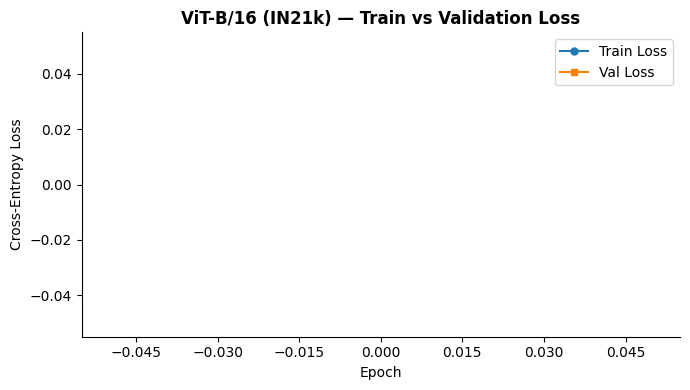

Saved → outputs/vit_b16/figures/vit_b16_loss_curve.png


In [22]:
epochs_ran = range(1, len(history['train_loss']) + 1)

# ── Print table ────────────────────────────────────────────────
print(f"{'Epoch':<8} {'Tr Loss':>10} {'Tr Acc':>8} {'Val Loss':>10} {'Val Acc':>8}")
print('─' * 50)
for ep, (tl, ta, vl, va) in enumerate(
    zip(history['train_loss'], history['train_acc'],
        history['val_loss'],   history['val_acc']), 1
):
    print(f'{ep:<8} {tl:>10.4f} {ta:>8.4f} {vl:>10.4f} {va:>8.4f}')
print()

# ── Plot loss curve ────────────────────────────────────────────
fig, ax = plt.subplots(figsize=(7, 4))
ax.plot(epochs_ran, history['train_loss'], label='Train Loss', marker='o', markersize=5)
ax.plot(epochs_ran, history['val_loss'],   label='Val Loss',   marker='s', markersize=5)
ax.set_title('ViT-B/16 (IN21k) — Train vs Validation Loss', fontweight='bold')
ax.set_xlabel('Epoch')
ax.set_ylabel('Cross-Entropy Loss')
ax.xaxis.set_major_locator(ticker.MaxNLocator(integer=True))
ax.legend()
ax.spines[['top', 'right']].set_visible(False)

plt.tight_layout()
fig.savefig(FIGURES_DIR / f'{EXPERIMENT_NAME}_loss_curve.png', dpi=150, bbox_inches='tight')
plt.show()
print(f'Saved → outputs/vit_b16/figures/{EXPERIMENT_NAME}_loss_curve.png')

## 9. Evaluation on Test Set

In [65]:
# ── Independent of training cell — requires Sections 1–7 + checkpoint registry ─
_prev_model     = globals().get('model',     None)
_prev_criterion = globals().get('criterion', None)

model     = timm.create_model(MODEL_NAME, pretrained=False, num_classes=NUM_CLASSES).to(device)
criterion = nn.CrossEntropyLoss()

ckpt = torch.load(CKPT_BASELINE, map_location=device, weights_only=False)
model.load_state_dict(ckpt['model_state'])
print(f'Loaded: {CKPT_BASELINE}')
print(f'epoch={ckpt["epoch"]}  val_loss={ckpt["val_loss"]:.4f}')

_, y_true, y_pred = run_epoch(test_loader, train_mode=False)

print('\nClassification Report (Test Set):')
print(classification_report(y_true, y_pred, target_names=CLASS_NAMES, digits=3))
print(f'Quadratic Weighted Kappa: {cohen_kappa_score(y_true, y_pred, weights="quadratic"):.4f}')

if _prev_model is not None:
    model     = _prev_model
    criterion = _prev_criterion


Loaded: /scratch/AML_G14_CW/outputs/vit_b16/checkpoints/vit_b16_best.pt
epoch=8  val_loss=0.8572


val:   0%|          | 0/330 [00:00<?, ?it/s]


Classification Report (Test Set):
               precision    recall  f1-score   support

        No DR      0.735     1.000     0.847      3872
         Mild      0.000     0.000     0.000       366
     Moderate      0.000     0.000     0.000       794
       Severe      0.000     0.000     0.000       131
Proliferative      0.000     0.000     0.000       106

     accuracy                          0.735      5269
    macro avg      0.147     0.200     0.169      5269
 weighted avg      0.540     0.735     0.623      5269

Quadratic Weighted Kappa: 0.0000


/scratch/AML_G14_CW/venv/lib/python3.12/site-packages/sklearn/metrics/_classification.py:1833: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", result.shape[0])
/scratch/AML_G14_CW/venv/lib/python3.12/site-packages/sklearn/metrics/_classification.py:1833: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", result.shape[0])
/scratch/AML_G14_CW/venv/lib/python3.12/site-packages/sklearn/metrics/_classification.py:1833: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", result.shape

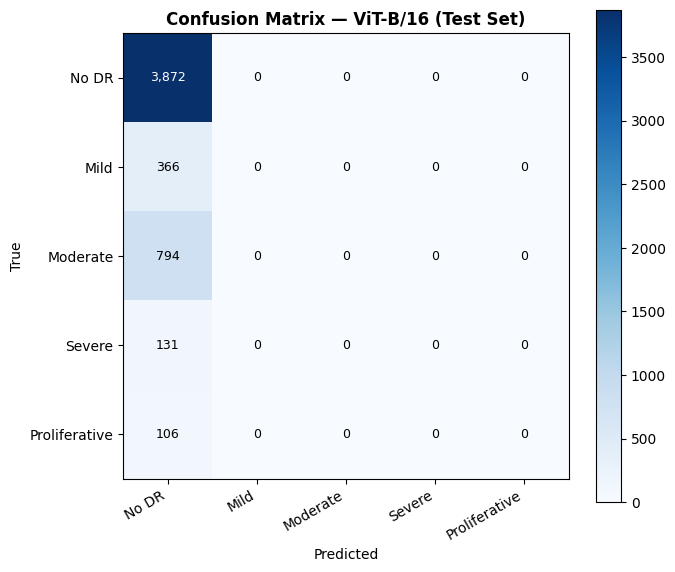

Saved → outputs/vit_b16/figures/vit_b16_confusion_matrix.png


In [24]:
cm = confusion_matrix(y_true, y_pred)

fig, ax = plt.subplots(figsize=(7, 6))
im = ax.imshow(cm, interpolation='nearest', cmap='Blues')
fig.colorbar(im, ax=ax)
ax.set_xticks(range(NUM_CLASSES)); ax.set_xticklabels(CLASS_NAMES, rotation=30, ha='right')
ax.set_yticks(range(NUM_CLASSES)); ax.set_yticklabels(CLASS_NAMES)
ax.set_xlabel('Predicted'); ax.set_ylabel('True')
ax.set_title('Confusion Matrix — ViT-B/16 (Test Set)', fontweight='bold')

thresh = cm.max() / 2
for i in range(cm.shape[0]):
    for j in range(cm.shape[1]):
        ax.text(j, i, f'{cm[i, j]:,}', ha='center', va='center', fontsize=9,
                color='white' if cm[i, j] > thresh else 'black')

plt.tight_layout()
fig.savefig(FIGURES_DIR / f'{EXPERIMENT_NAME}_confusion_matrix.png', dpi=150, bbox_inches='tight')
plt.show()
print(f'Saved → outputs/vit_b16/figures/{EXPERIMENT_NAME}_confusion_matrix.png')

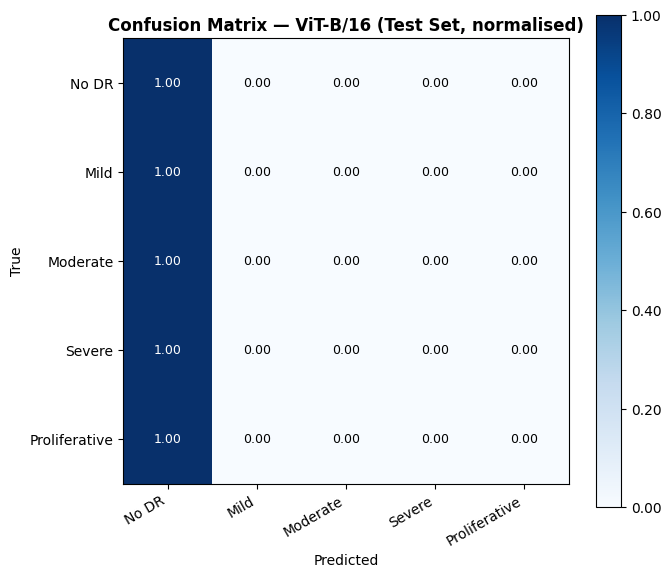

Saved → outputs/vit_b16/figures/vit_b16_confusion_matrix_normalised.png


In [25]:
cm_norm = cm.astype(float) / cm.sum(axis=1, keepdims=True)

fig, ax = plt.subplots(figsize=(7, 6))
im = ax.imshow(cm_norm, interpolation='nearest', cmap='Blues', vmin=0, vmax=1)
fig.colorbar(im, ax=ax, format='%.2f')
ax.set_xticks(range(NUM_CLASSES)); ax.set_xticklabels(CLASS_NAMES, rotation=30, ha='right')
ax.set_yticks(range(NUM_CLASSES)); ax.set_yticklabels(CLASS_NAMES)
ax.set_xlabel('Predicted'); ax.set_ylabel('True')
ax.set_title('Confusion Matrix — ViT-B/16 (Test Set, normalised)', fontweight='bold')

thresh = 0.5
for i in range(cm_norm.shape[0]):
    for j in range(cm_norm.shape[1]):
        ax.text(j, i, f'{cm_norm[i, j]:.2f}', ha='center', va='center', fontsize=9,
                color='white' if cm_norm[i, j] > thresh else 'black')

plt.tight_layout()
fig.savefig(FIGURES_DIR / f'{EXPERIMENT_NAME}_confusion_matrix_normalised.png', dpi=150, bbox_inches='tight')
plt.show()
print(f'Saved → outputs/vit_b16/figures/{EXPERIMENT_NAME}_confusion_matrix_normalised.png')

## 10. Results Summary

In [66]:
qwk    = cohen_kappa_score(y_true, y_pred, weights='quadratic')
acc    = accuracy_score(y_true, y_pred)
f1_per = f1_score(y_true, y_pred, average=None, labels=list(range(5)))

print('=' * 52)
print('  ViT-B/16 (ImageNet-21k) — TEST SET RESULTS')
print('=' * 52)
print(f'  Test QWK      : {qwk:.4f}')
print(f'  Test Accuracy : {acc:.4f}')
print()
print('  Per-class F1:')
for name, f1 in zip(CLASS_NAMES, f1_per):
    print(f'    {name:<18}: {f1:.4f}')
print('=' * 52)

  ViT-B/16 (ImageNet-21k) — TEST SET RESULTS
  Test QWK      : 0.0000
  Test Accuracy : 0.7349

  Per-class F1:
    No DR             : 0.8472
    Mild              : 0.0000
    Moderate          : 0.0000
    Severe            : 0.0000
    Proliferative     : 0.0000


## 11. Experiment 1 — Class Imbalance Handling

**Hypothesis:** The 36.4× class imbalance (Grade 0 = 73.5% vs Grade 4 = 2.0%) biases the baseline
towards majority classes and suppresses minority-class recall.
Combining three complementary techniques should improve QWK — especially on under-represented grades —
without changing the architecture or hyper-parameters.

**Techniques (all combined):**
| Technique | Where it acts | What it does |
|---|---|---|
| `WeightedRandomSampler` | Data pipeline | Over-samples minority grades so each epoch sees near-balanced class frequencies |
| Class-weight alpha (`α`) | Loss (per-class) | Scales the CE loss for each class by its inverse frequency |
| `FocalLoss` (γ=2) | Loss (per-sample) | Down-weights easy/well-classified examples; focuses training on hard minority samples |

> **Note:** Cells 1–10 (baseline) must be run first — this section reuses `run_epoch`, `train_ds`,
> `val_loader`, `qwk`, `acc`, and `f1_per` from those cells.

In [67]:
import torch.nn as nn
import torch.nn.functional as F
from torch.utils.data import WeightedRandomSampler
from sklearn.utils.class_weight import compute_class_weight

In [68]:
class FocalLoss(nn.Module):
    """
    Focal Loss with optional per-class alpha weighting.
      alpha : Tensor[NUM_CLASSES] or None — pass None for no class weighting (gamma only).
      gamma : focusing parameter; (1-pt)^gamma down-weights easy examples.
    """
    def __init__(self, alpha=None, gamma: float = 2.0):
        super().__init__()
        if alpha is not None:
            self.register_buffer('alpha', alpha)
        else:
            self.alpha = None
        self.gamma = gamma

    def forward(self, logits: torch.Tensor, target: torch.Tensor) -> torch.Tensor:
        ce = F.cross_entropy(logits, target, weight=self.alpha, reduction='none')
        pt = torch.exp(-ce)
        return ((1.0 - pt) ** self.gamma * ce).mean()

print('FocalLoss defined.')


FocalLoss defined.


In [69]:
# ── 1. Inverse-frequency class weights ───────────────────────────────────────
train_labels = train_df['level'].values

class_weights_np = compute_class_weight(
    class_weight='balanced',
    classes=np.arange(NUM_CLASSES),
    y=train_labels,
)
class_weights_t = torch.tensor(class_weights_np, dtype=torch.float32).to(device)

print('Class weights (inverse-freq, balanced):')
for name, w in zip(CLASS_NAMES, class_weights_np):
    print(f'  {name:<20}: {w:.4f}')

# ── 2. Per-sample weights for WeightedRandomSampler ──────────────────────────
sample_weights_t = torch.as_tensor(class_weights_np[train_labels], dtype=torch.double)

exp1_sampler = WeightedRandomSampler(
    weights=sample_weights_t,
    num_samples=len(sample_weights_t),
    replacement=True,
)

# ── 3. New train loader (sampler replaces shuffle); val/test loaders unchanged ─
exp1_train_loader = DataLoader(
    train_ds,
    batch_size=BATCH_SIZE,
    sampler=exp1_sampler,
    num_workers=NUM_WORKERS,
    pin_memory=True,
    drop_last=True,
    persistent_workers=NUM_WORKERS > 0,
)

print(f'\nExp1 train loader : {len(exp1_train_loader)} batches/epoch')
print(f'Val loader (reuse): {len(val_loader)} batches/epoch')
print(f'Test loader (reuse): {len(test_loader)} batches/epoch')

Class weights (inverse-freq, balanced):
  No DR               : 0.2722
  Mild                : 2.8758
  Moderate            : 1.3276
  Severe              : 8.0484
  Proliferative       : 9.9145

Exp1 train loader : 1536 batches/epoch
Val loader (reuse): 330 batches/epoch
Test loader (reuse): 330 batches/epoch


In [70]:
set_seed(SEED)

# ── Fresh model (independent weights — fair comparison with baseline) ─────────
exp1_model = timm.create_model(MODEL_NAME, pretrained=True, num_classes=NUM_CLASSES)
exp1_model = exp1_model.to(device)

# ── FocalLoss: alpha = inverse-freq class weights, gamma = 2 ─────────────────
# exp1_criterion = FocalLoss(alpha=class_weights_t, gamma=2.0)
exp1_criterion = FocalLoss(alpha=None, gamma=2.0)

# ── Same hyper-parameters as baseline ────────────────────────────────────────
exp1_optimizer = torch.optim.AdamW(exp1_model.parameters(), lr=LR, weight_decay=WEIGHT_DECAY)
exp1_scheduler = torch.optim.lr_scheduler.CosineAnnealingLR(exp1_optimizer, T_max=EPOCHS)
exp1_scaler    = torch.amp.GradScaler('cuda', enabled=use_amp)

# ── Output directories ────────────────────────────────────────────────────────
EXP1_OUT_DIR  = ROOT / 'outputs' / 'vit_b16_exp1'
EXP1_CKPT_DIR = EXP1_OUT_DIR / 'checkpoints'
EXP1_FIG_DIR  = EXP1_OUT_DIR / 'figures'
for d in (EXP1_CKPT_DIR, EXP1_FIG_DIR):
    d.mkdir(parents=True, exist_ok=True)

EXP1_BEST_PATH = EXP1_CKPT_DIR / 'vit_b16_exp1_best.pt'

print(f'Model     : {MODEL_NAME}')
print(f'Criterion : FocalLoss(gamma=2.0, alpha=class_weights)')
print(f'Optimiser : AdamW  lr={LR}  wd={WEIGHT_DECAY}')
print(f'Checkpts  : {EXP1_CKPT_DIR}')
print(f'Figures   : {EXP1_FIG_DIR}')

Model     : vit_base_patch16_224.augreg_in21k_ft_in1k
Criterion : FocalLoss(gamma=2.0, alpha=class_weights)
Optimiser : AdamW  lr=0.0001  wd=0.01
Checkpts  : /scratch/AML_G14_CW/outputs/vit_b16_exp1/checkpoints
Figures   : /scratch/AML_G14_CW/outputs/vit_b16_exp1/figures


In [15]:
# ── Stash baseline bindings (safe if baseline hasn't been run) ────────────────
_baseline_model     = globals().get('model',     None)
_baseline_criterion = globals().get('criterion', None)
_baseline_optimizer = globals().get('optimizer', None)
_baseline_scaler    = globals().get('scaler',    None)

model     = exp1_model
criterion = exp1_criterion
optimizer = exp1_optimizer
scaler    = exp1_scaler

# ── Training loop (identical structure to baseline) ───────────────────────────
exp1_best_val_loss = float('inf')
exp1_patience_left = EARLY_STOPPING_PATIENCE
exp1_history = {'train_loss': [], 'val_loss': [], 'train_acc': [], 'val_acc': []}

print(f"{'Epoch':<8} {'Tr Loss':>10} {'Tr Acc':>8} {'Val Loss':>10} {'Val Acc':>8}")
print('─' * 50)

for epoch in range(1, EPOCHS + 1):
    tr_loss, tr_labels, tr_preds = run_epoch(exp1_train_loader, train_mode=True)
    vl_loss, vl_labels, vl_preds = run_epoch(val_loader,        train_mode=False)
    exp1_scheduler.step()

    tr_acc = accuracy_score(tr_labels, tr_preds)
    vl_acc = accuracy_score(vl_labels, vl_preds)

    exp1_history['train_loss'].append(tr_loss)
    exp1_history['val_loss'].append(vl_loss)
    exp1_history['train_acc'].append(tr_acc)
    exp1_history['val_acc'].append(vl_acc)

    marker = ''
    if vl_loss < exp1_best_val_loss:
        exp1_best_val_loss = vl_loss
        exp1_patience_left = EARLY_STOPPING_PATIENCE
        torch.save({'epoch': epoch, 'model_state': model.state_dict(),
                    'val_loss': vl_loss}, EXP1_BEST_PATH)
        marker = '  ← best'
    else:
        exp1_patience_left -= 1

    print(f'{epoch:<8} {tr_loss:>10.4f} {tr_acc:>8.4f} {vl_loss:>10.4f} {vl_acc:>8.4f}{marker}')

    if exp1_patience_left == 0:
        print(f'\nEarly stopping at epoch {epoch}.')
        break

print(f'\nBest val loss: {exp1_best_val_loss:.4f}  →  {EXP1_BEST_PATH}')

# ── Restore baseline bindings ─────────────────────────────────────────────────
if _baseline_model is not None:
    model     = _baseline_model
    criterion = _baseline_criterion
    optimizer = _baseline_optimizer
    scaler    = _baseline_scaler

Epoch       Tr Loss   Tr Acc   Val Loss  Val Acc
──────────────────────────────────────────────────


train:   0%|          | 0/1536 [00:00<?, ?it/s]

val:   0%|          | 0/330 [00:00<?, ?it/s]

1            1.0472   0.2882     0.7145   0.5608  ← best


train:   0%|          | 0/1536 [00:00<?, ?it/s]

...

val:   0%|          | 0/330 [00:00<?, ?it/s]

9            0.7646   0.3950     0.7072   0.5409


train:   0%|          | 0/1536 [00:00<?, ?it/s]

val:   0%|          | 0/330 [00:00<?, ?it/s]

10           0.7120   0.4272     0.6948   0.5420

Early stopping at epoch 10.

Best val loss: 0.6786  →  /scratch/AML_G14_CW/outputs/vit_b16_exp1/checkpoints/vit_b16_exp1_best.pt


Epoch       Tr Loss   Tr Acc   Val Loss  Val Acc
──────────────────────────────────────────────────
1            1.0472   0.2882     0.7145   0.5608
2            0.8381   0.3737     0.8144   0.2148
3            0.7873   0.3917     1.2290   0.0736
4            0.7549   0.4078     0.7774   0.4883
5            0.7412   0.4154     0.6786   0.4769
6            0.7228   0.4257     0.7609   0.4322
7            0.7001   0.4323     0.7324   0.3464
8            0.9400   0.2980     0.8806   0.1179
9            0.7646   0.3950     0.7072   0.5409
10           0.7120   0.4272     0.6948   0.5420



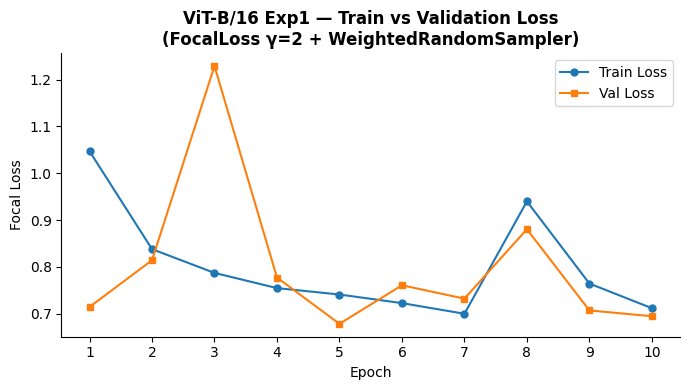

Saved → outputs/vit_b16_exp1/figures/vit_b16_exp1_loss_curve.png


In [19]:
epochs_ran_exp1 = range(1, len(exp1_history['train_loss']) + 1)

# ── Print table ───────────────────────────────────────────────────────────────
print(f"{'Epoch':<8} {'Tr Loss':>10} {'Tr Acc':>8} {'Val Loss':>10} {'Val Acc':>8}")
print('─' * 50)
for ep, (tl, ta, vl, va) in enumerate(
    zip(exp1_history['train_loss'], exp1_history['train_acc'],
        exp1_history['val_loss'],   exp1_history['val_acc']), 1
):
    print(f'{ep:<8} {tl:>10.4f} {ta:>8.4f} {vl:>10.4f} {va:>8.4f}')
print()

# ── Plot loss curve ────────────────────────────────────────────────────────────
fig, ax = plt.subplots(figsize=(7, 4))
ax.plot(epochs_ran_exp1, exp1_history['train_loss'], label='Train Loss', marker='o', markersize=5)
ax.plot(epochs_ran_exp1, exp1_history['val_loss'],   label='Val Loss',   marker='s', markersize=5)
ax.set_title('ViT-B/16 Exp1 — Train vs Validation Loss\n(FocalLoss γ=2 + WeightedRandomSampler)', fontweight='bold')
ax.set_xlabel('Epoch')
ax.set_ylabel('Focal Loss')
ax.xaxis.set_major_locator(ticker.MaxNLocator(integer=True))
ax.legend()
ax.spines[['top', 'right']].set_visible(False)

plt.tight_layout()
fig.savefig(EXP1_FIG_DIR / 'vit_b16_exp1_loss_curve.png', dpi=150, bbox_inches='tight')
plt.show()
print(f'Saved → outputs/vit_b16_exp1/figures/vit_b16_exp1_loss_curve.png')

In [71]:
# ── Independent of training cell — requires Sections 1–7 + checkpoint registry ─
_prev_model     = globals().get('model',     None)
_prev_criterion = globals().get('criterion', None)

model     = timm.create_model(MODEL_NAME, pretrained=False, num_classes=NUM_CLASSES).to(device)
criterion = nn.CrossEntropyLoss()

ckpt = torch.load(CKPT_EXP1, map_location=device, weights_only=False)
model.load_state_dict(ckpt['model_state'])
print(f'Exp1: loaded {CKPT_EXP1.name}  (epoch {ckpt["epoch"]}, val_loss={ckpt["val_loss"]:.4f})')

_, exp1_y_true, exp1_y_pred = run_epoch(test_loader, train_mode=False)

print('\nExp1 Classification Report (Test Set):')
print(classification_report(exp1_y_true, exp1_y_pred, target_names=CLASS_NAMES, digits=3))

if _prev_model is not None:
    model     = _prev_model
    criterion = _prev_criterion


Exp1: loaded vit_b16_exp1_best.pt  (epoch 5, val_loss=0.6786)


val:   0%|          | 0/330 [00:00<?, ?it/s]


Exp1 Classification Report (Test Set):
               precision    recall  f1-score   support

        No DR      0.824     0.570     0.674      3872
         Mild      0.070     0.202     0.104       366
     Moderate      0.251     0.282     0.266       794
       Severe      0.142     0.420     0.212       131
Proliferative      0.234     0.547     0.328       106

     accuracy                          0.497      5269
    macro avg      0.304     0.404     0.317      5269
 weighted avg      0.657     0.497     0.554      5269



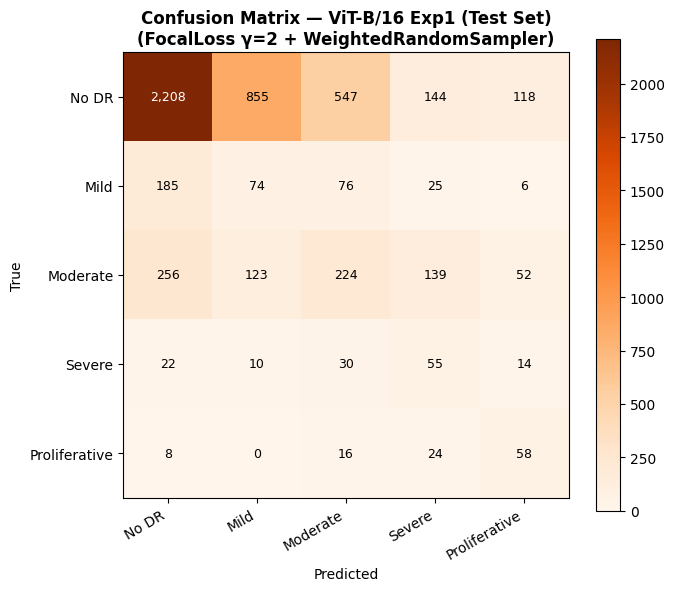

Saved → outputs/vit_b16_exp1/figures/vit_b16_exp1_confusion_matrix.png


In [32]:
cm_exp1 = confusion_matrix(exp1_y_true, exp1_y_pred)

fig, ax = plt.subplots(figsize=(7, 6))
im = ax.imshow(cm_exp1, interpolation='nearest', cmap='Oranges')
fig.colorbar(im, ax=ax)
ax.set_xticks(range(NUM_CLASSES)); ax.set_xticklabels(CLASS_NAMES, rotation=30, ha='right')
ax.set_yticks(range(NUM_CLASSES)); ax.set_yticklabels(CLASS_NAMES)
ax.set_xlabel('Predicted'); ax.set_ylabel('True')
ax.set_title('Confusion Matrix — ViT-B/16 Exp1 (Test Set)\n(FocalLoss γ=2 + WeightedRandomSampler)', fontweight='bold')

thresh = cm_exp1.max() / 2
for i in range(cm_exp1.shape[0]):
    for j in range(cm_exp1.shape[1]):
        ax.text(j, i, f'{cm_exp1[i, j]:,}', ha='center', va='center', fontsize=9,
                color='white' if cm_exp1[i, j] > thresh else 'black')

plt.tight_layout()
fig.savefig(EXP1_FIG_DIR / 'vit_b16_exp1_confusion_matrix.png', dpi=150, bbox_inches='tight')
plt.show()
print(f'Saved → outputs/vit_b16_exp1/figures/vit_b16_exp1_confusion_matrix.png')

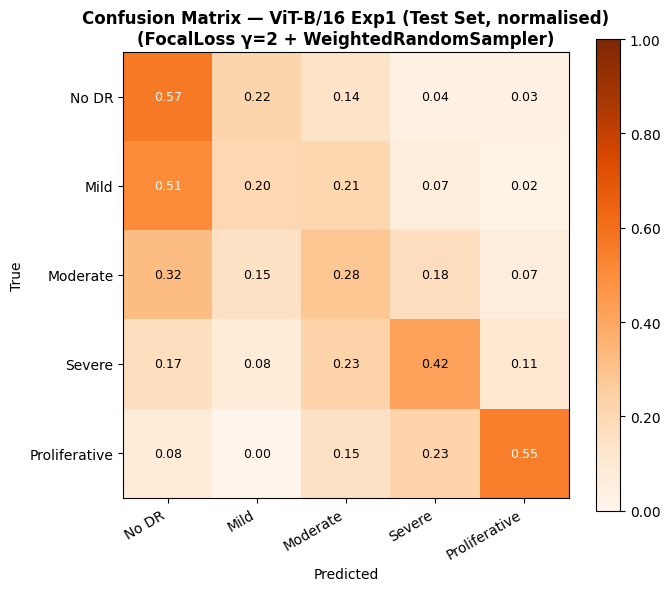

Saved → outputs/vit_b16_exp1/figures/vit_b16_exp1_confusion_matrix_normalised.png


In [33]:
cm_exp1_norm = cm_exp1.astype(float) / cm_exp1.sum(axis=1, keepdims=True)

fig, ax = plt.subplots(figsize=(7, 6))
im = ax.imshow(cm_exp1_norm, interpolation='nearest', cmap='Oranges', vmin=0, vmax=1)
fig.colorbar(im, ax=ax, format='%.2f')
ax.set_xticks(range(NUM_CLASSES)); ax.set_xticklabels(CLASS_NAMES, rotation=30, ha='right')
ax.set_yticks(range(NUM_CLASSES)); ax.set_yticklabels(CLASS_NAMES)
ax.set_xlabel('Predicted'); ax.set_ylabel('True')
ax.set_title('Confusion Matrix — ViT-B/16 Exp1 (Test Set, normalised)\n(FocalLoss γ=2 + WeightedRandomSampler)', fontweight='bold')

thresh = 0.5
for i in range(cm_exp1_norm.shape[0]):
    for j in range(cm_exp1_norm.shape[1]):
        ax.text(j, i, f'{cm_exp1_norm[i, j]:.2f}', ha='center', va='center', fontsize=9,
                color='white' if cm_exp1_norm[i, j] > thresh else 'black')

plt.tight_layout()
fig.savefig(EXP1_FIG_DIR / 'vit_b16_exp1_confusion_matrix_normalised.png', dpi=150, bbox_inches='tight')
plt.show()
print(f'Saved → outputs/vit_b16_exp1/figures/vit_b16_exp1_confusion_matrix_normalised.png')

In [72]:
# ── Exp1 summary metrics ───────────────────────────────────────────────────────
exp1_qwk    = cohen_kappa_score(exp1_y_true, exp1_y_pred, weights='quadratic')
exp1_acc    = accuracy_score(exp1_y_true, exp1_y_pred)
exp1_f1_per = f1_score(exp1_y_true, exp1_y_pred, average=None, labels=list(range(5)))

# ── Side-by-side comparison (baseline variables: qwk, acc, f1_per) ─────────────
print('=' * 62)
print(f'  {"Metric":<25} {"Baseline":>10}  {"Exp1 (WRS+Focal)":>16}')
print('=' * 62)
qwk_arrow = '▲' if exp1_qwk > qwk else '▼'
print(f'  {"Test QWK":<25} {qwk:>10.4f}  {exp1_qwk:>16.4f}  {qwk_arrow}')
print(f'  {"Test Accuracy":<25} {acc:>10.4f}  {exp1_acc:>16.4f}')
print()
print(f'  Per-class F1:')
for name, f1_b, f1_e in zip(CLASS_NAMES, f1_per, exp1_f1_per):
    delta = f1_e - f1_b
    print(f'    {name:<21}: {f1_b:.4f}  →  {f1_e:.4f}  ({delta:+.4f})')
print('=' * 62)
print(f'  QWK delta: {exp1_qwk - qwk:+.4f}')
print('=' * 62)

  Metric                      Baseline  Exp1 (WRS+Focal)
  Test QWK                      0.0000            0.3480  ▲
  Test Accuracy                 0.7349            0.4971

  Per-class F1:
    No DR                : 0.8472  →  0.6741  (-0.1731)
    Mild                 : 0.0000  →  0.1036  (+0.1036)
    Moderate             : 0.0000  →  0.2656  (+0.2656)
    Severe               : 0.0000  →  0.2124  (+0.2124)
    Proliferative        : 0.0000  →  0.3277  (+0.3277)
  QWK delta: +0.3480


## 12. Experiment 2 — Enhanced Augmentation

**Hypothesis:** The baseline training transform (resize → crop → HFlip) omits several augmentations
that improve generalisation on retinal images. Adding RandomVerticalFlip, RandomRotation, ColorJitter,
and RandomAffine should reduce overfitting and improve QWK — especially for minority classes with few
training examples.

**Additions over Exp1:**

| Augmentation | Rationale |
|---|---|
| `RandomVerticalFlip(p=0.5)` | Fundus images have no canonical up/down orientation |
| `RandomRotation(15°)` | Rotation-invariance for vessel patterns |
| `ColorJitter(brightness=0.1, contrast=0.1, saturation=0.05, hue=0.02)` | Illumination robustness |
| `RandomAffine(translate=0.05, scale=0.95–1.05)` | Minor camera-position variance |

> **Carried forward from Exp1:** WeightedRandomSampler (`exp1_sampler`), FocalLoss (γ=2), `class_weights_t`.

In [73]:
exp2_train_transform = transforms.Compose([
    transforms.Resize(int(IMAGE_SIZE * 1.14)),
    transforms.RandomCrop(IMAGE_SIZE),
    transforms.RandomHorizontalFlip(p=0.5),
    transforms.RandomVerticalFlip(p=0.5),
    transforms.RandomApply([transforms.RandomRotation(degrees=15)], p=0.5),
    transforms.RandomApply([
        transforms.ColorJitter(brightness=0.1, contrast=0.1, saturation=0.05, hue=0.02)
    ], p=0.3),
    transforms.RandomApply([
        transforms.RandomAffine(degrees=0, translate=(0.05, 0.05), scale=(0.95, 1.05))
    ], p=0.3),
    transforms.ToTensor(),
    transforms.Normalize(VIT_MEAN, VIT_STD),
])

exp2_train_ds = DRDataset(train_df, TRAIN_DIR, transform=exp2_train_transform)

# Reuse exp1_sampler (WeightedRandomSampler) — same class-balance strategy
exp2_train_loader = DataLoader(
    exp2_train_ds,
    batch_size=BATCH_SIZE,
    sampler=exp1_sampler,
    num_workers=NUM_WORKERS,
    pin_memory=True,
    drop_last=True,
    persistent_workers=NUM_WORKERS > 0,
)

print(f'Exp2 train loader: {len(exp2_train_loader)} batches/epoch  (augmented transform)')
print('Added: RandomVerticalFlip, RandomRotation(15°), ColorJitter, RandomAffine')

Exp2 train loader: 1536 batches/epoch  (augmented transform)
Added: RandomVerticalFlip, RandomRotation(15°), ColorJitter, RandomAffine


In [74]:
set_seed(SEED)
exp2_model     = timm.create_model(MODEL_NAME, pretrained=True, num_classes=NUM_CLASSES).to(device)
exp2_criterion = FocalLoss(alpha=None, gamma=2.0)
exp2_optimizer = torch.optim.AdamW(exp2_model.parameters(), lr=LR, weight_decay=WEIGHT_DECAY)
exp2_scheduler = torch.optim.lr_scheduler.CosineAnnealingLR(exp2_optimizer, T_max=EPOCHS)
exp2_scaler    = torch.amp.GradScaler('cuda', enabled=use_amp)

EXP2_OUT_DIR  = ROOT / 'outputs' / 'vit_b16_exp2'
EXP2_CKPT_DIR = EXP2_OUT_DIR / 'checkpoints'
EXP2_FIG_DIR  = EXP2_OUT_DIR / 'figures'
for d in (EXP2_CKPT_DIR, EXP2_FIG_DIR):
    d.mkdir(parents=True, exist_ok=True)

EXP2_BEST_PATH = EXP2_CKPT_DIR / 'vit_b16_exp2_best.pt'

print(f'Exp2 model ready.')
print(f'Checkpoints → {EXP2_CKPT_DIR}')
print(f'Figures     → {EXP2_FIG_DIR}')

Exp2 model ready.
Checkpoints → /scratch/AML_G14_CW/outputs/vit_b16_exp2/checkpoints
Figures     → /scratch/AML_G14_CW/outputs/vit_b16_exp2/figures


In [63]:
_e2_baseline_model     = globals().get('model',     None)
_e2_baseline_criterion = globals().get('criterion', None)
_e2_baseline_optimizer = globals().get('optimizer', None)
_e2_baseline_scaler    = globals().get('scaler',    None)

model, criterion, optimizer, scaler = exp2_model, exp2_criterion, exp2_optimizer, exp2_scaler

exp2_history       = {'train_loss': [], 'val_loss': [], 'train_acc': [], 'val_acc': []}
exp2_best_val_loss = float('inf')
exp2_patience_left = EARLY_STOPPING_PATIENCE

print(f"{'Epoch':<8} {'Tr Loss':>10} {'Tr Acc':>8} {'Val Loss':>10} {'Val Acc':>8}")
print('─' * 50)

for epoch in range(1, EPOCHS + 1):
    tr_loss, tr_labels, tr_preds = run_epoch(exp2_train_loader, train_mode=True)
    vl_loss, vl_labels, vl_preds = run_epoch(val_loader,        train_mode=False)
    exp2_scheduler.step()

    tr_acc = accuracy_score(tr_labels, tr_preds)
    vl_acc = accuracy_score(vl_labels, vl_preds)

    exp2_history['train_loss'].append(tr_loss)
    exp2_history['val_loss'].append(vl_loss)
    exp2_history['train_acc'].append(tr_acc)
    exp2_history['val_acc'].append(vl_acc)

    marker = ''
    if vl_loss < exp2_best_val_loss:
        exp2_best_val_loss = vl_loss
        exp2_patience_left = EARLY_STOPPING_PATIENCE
        torch.save({'epoch': epoch, 'model_state': model.state_dict(),
                    'val_loss': vl_loss}, EXP2_BEST_PATH)
        marker = '  ← best'
    else:
        exp2_patience_left -= 1

    print(f'{epoch:<8} {tr_loss:>10.4f} {tr_acc:>8.4f} {vl_loss:>10.4f} {vl_acc:>8.4f}{marker}')

    if exp2_patience_left == 0:
        print(f'\nEarly stopping at epoch {epoch}.')
        break

print(f'\nBest val loss: {exp2_best_val_loss:.4f}  →  {EXP2_BEST_PATH}')

if _e2_baseline_model is not None:
    model, criterion, optimizer, scaler = (
        _e2_baseline_model, _e2_baseline_criterion,
        _e2_baseline_optimizer, _e2_baseline_scaler
    )

Epoch       Tr Loss   Tr Acc   Val Loss  Val Acc
──────────────────────────────────────────────────


train:   0%|          | 0/1536 [00:00<?, ?it/s]

val:   0%|          | 0/330 [00:00<?, ?it/s]

1            0.7588   0.4283     0.7425   0.5373  ← best


train:   0%|          | 0/1536 [00:00<?, ?it/s]

...

val:   0%|          | 0/330 [00:00<?, ?it/s]

13           0.1894   0.7917     0.5739   0.4669


train:   0%|          | 0/1536 [00:00<?, ?it/s]

val:   0%|          | 0/330 [00:00<?, ?it/s]

14           0.1672   0.8108     0.5793   0.4563

Early stopping at epoch 14.

Best val loss: 0.4794  →  /scratch/AML_G14_CW/outputs/vit_b16_exp2/checkpoints/vit_b16_exp2_best.pt


Epoch       Tr Loss   Tr Acc   Val Loss  Val Acc
──────────────────────────────────────────────────
1            0.7588   0.4283     0.7425   0.5373
2            0.6161   0.4903     0.6656   0.2896
3            0.5548   0.5193     1.0239   0.2653
4            0.4854   0.5565     0.7652   0.3078
5            0.4368   0.5894     0.6454   0.3075
6            0.3906   0.6195     0.5543   0.4597
7            0.3454   0.6518     0.5976   0.3862
8            0.3169   0.6748     0.5235   0.4783
9            0.2851   0.7014     0.4794   0.5483
10           0.2641   0.7225     0.5429   0.5251
11           0.2405   0.7362     0.5367   0.4786
12           0.2137   0.7635     0.5185   0.4802
13           0.1894   0.7917     0.5739   0.4669
14           0.1672   0.8108     0.5793   0.4563



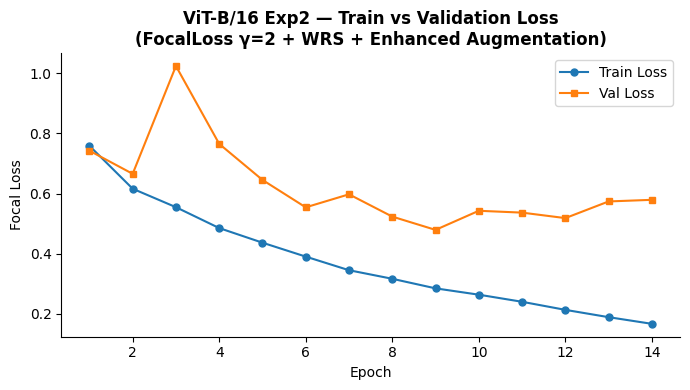

Saved → outputs/vit_b16_exp2/figures/vit_b16_exp2_loss_curve.png


In [64]:
epochs_ran_exp2 = range(1, len(exp2_history['train_loss']) + 1)

print(f"{'Epoch':<8} {'Tr Loss':>10} {'Tr Acc':>8} {'Val Loss':>10} {'Val Acc':>8}")
print('─' * 50)
for ep, (tl, ta, vl, va) in enumerate(
    zip(exp2_history['train_loss'], exp2_history['train_acc'],
        exp2_history['val_loss'],   exp2_history['val_acc']), 1
):
    print(f'{ep:<8} {tl:>10.4f} {ta:>8.4f} {vl:>10.4f} {va:>8.4f}')
print()

fig, ax = plt.subplots(figsize=(7, 4))
ax.plot(epochs_ran_exp2, exp2_history['train_loss'], label='Train Loss', marker='o', markersize=5)
ax.plot(epochs_ran_exp2, exp2_history['val_loss'],   label='Val Loss',   marker='s', markersize=5)
ax.set_title('ViT-B/16 Exp2 — Train vs Validation Loss\n(FocalLoss γ=2 + WRS + Enhanced Augmentation)', fontweight='bold')
ax.set_xlabel('Epoch'); ax.set_ylabel('Focal Loss')
ax.xaxis.set_major_locator(ticker.MaxNLocator(integer=True))
ax.legend(); ax.spines[['top', 'right']].set_visible(False)
plt.tight_layout()
fig.savefig(EXP2_FIG_DIR / 'vit_b16_exp2_loss_curve.png', dpi=150, bbox_inches='tight')
plt.show()
print('Saved → outputs/vit_b16_exp2/figures/vit_b16_exp2_loss_curve.png')

In [75]:
# ── Independent of training cell — requires Sections 1–7 + checkpoint registry ─
_prev_model     = globals().get('model',     None)
_prev_criterion = globals().get('criterion', None)

model     = timm.create_model(MODEL_NAME, pretrained=False, num_classes=NUM_CLASSES).to(device)
criterion = nn.CrossEntropyLoss()

ckpt = torch.load(CKPT_EXP2, map_location=device, weights_only=False)
model.load_state_dict(ckpt['model_state'])
print(f'Exp2: loaded {CKPT_EXP2.name}  (epoch {ckpt["epoch"]}, val_loss={ckpt["val_loss"]:.4f})')

_, exp2_y_true, exp2_y_pred = run_epoch(test_loader, train_mode=False)

print('\nExp2 Classification Report (Test Set):')
print(classification_report(exp2_y_true, exp2_y_pred, target_names=CLASS_NAMES, digits=3))

if _prev_model is not None:
    model     = _prev_model
    criterion = _prev_criterion


Exp2: loaded vit_b16_exp2_best.pt  (epoch 9, val_loss=0.4794)


val:   0%|          | 0/330 [00:00<?, ?it/s]


Exp2 Classification Report (Test Set):
               precision    recall  f1-score   support

        No DR      0.862     0.605     0.711      3872
         Mild      0.110     0.481     0.179       366
     Moderate      0.429     0.346     0.383       794
       Severe      0.265     0.427     0.327       131
Proliferative      0.550     0.519     0.534       106

     accuracy                          0.551      5269
    macro avg      0.443     0.476     0.427      5269
 weighted avg      0.723     0.551     0.611      5269



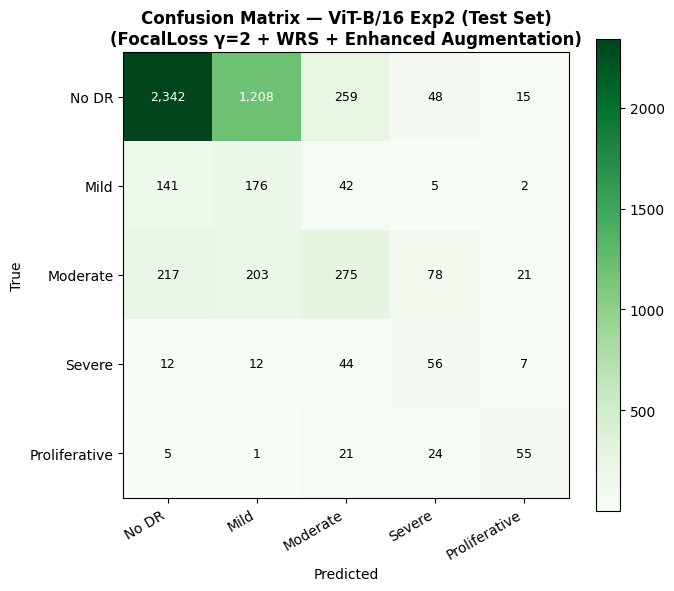

Saved → outputs/vit_b16_exp2/figures/vit_b16_exp2_confusion_matrix.png


In [38]:
cm_exp2 = confusion_matrix(exp2_y_true, exp2_y_pred)

fig, ax = plt.subplots(figsize=(7, 6))
im = ax.imshow(cm_exp2, interpolation='nearest', cmap='Greens')
fig.colorbar(im, ax=ax)
ax.set_xticks(range(NUM_CLASSES)); ax.set_xticklabels(CLASS_NAMES, rotation=30, ha='right')
ax.set_yticks(range(NUM_CLASSES)); ax.set_yticklabels(CLASS_NAMES)
ax.set_xlabel('Predicted'); ax.set_ylabel('True')
ax.set_title('Confusion Matrix — ViT-B/16 Exp2 (Test Set)\n(FocalLoss γ=2 + WRS + Enhanced Augmentation)', fontweight='bold')

thresh = cm_exp2.max() / 2
for i in range(cm_exp2.shape[0]):
    for j in range(cm_exp2.shape[1]):
        ax.text(j, i, f'{cm_exp2[i, j]:,}', ha='center', va='center', fontsize=9,
                color='white' if cm_exp2[i, j] > thresh else 'black')

plt.tight_layout()
fig.savefig(EXP2_FIG_DIR / 'vit_b16_exp2_confusion_matrix.png', dpi=150, bbox_inches='tight')
plt.show()
print('Saved → outputs/vit_b16_exp2/figures/vit_b16_exp2_confusion_matrix.png')

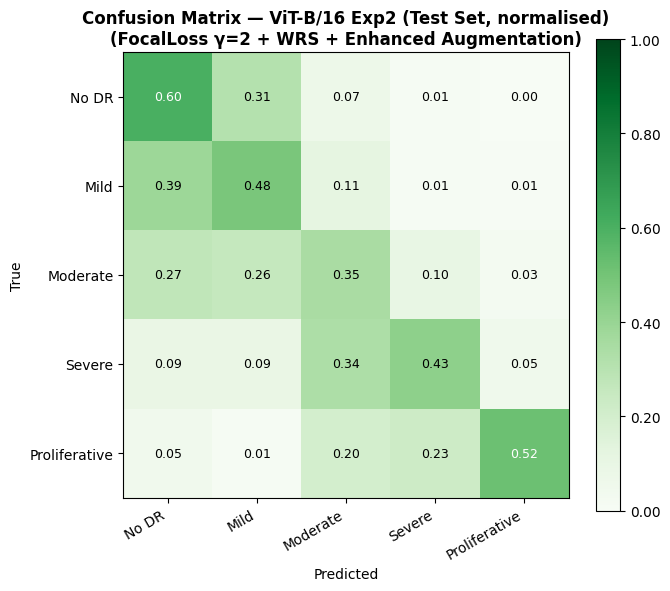

Saved → outputs/vit_b16_exp2/figures/vit_b16_exp2_confusion_matrix_normalised.png


In [39]:
cm_exp2_norm = cm_exp2.astype(float) / cm_exp2.sum(axis=1, keepdims=True)

fig, ax = plt.subplots(figsize=(7, 6))
im = ax.imshow(cm_exp2_norm, interpolation='nearest', cmap='Greens', vmin=0, vmax=1)
fig.colorbar(im, ax=ax, format='%.2f')
ax.set_xticks(range(NUM_CLASSES)); ax.set_xticklabels(CLASS_NAMES, rotation=30, ha='right')
ax.set_yticks(range(NUM_CLASSES)); ax.set_yticklabels(CLASS_NAMES)
ax.set_xlabel('Predicted'); ax.set_ylabel('True')
ax.set_title('Confusion Matrix — ViT-B/16 Exp2 (Test Set, normalised)\n(FocalLoss γ=2 + WRS + Enhanced Augmentation)', fontweight='bold')

thresh = 0.5
for i in range(cm_exp2_norm.shape[0]):
    for j in range(cm_exp2_norm.shape[1]):
        ax.text(j, i, f'{cm_exp2_norm[i, j]:.2f}', ha='center', va='center', fontsize=9,
                color='white' if cm_exp2_norm[i, j] > thresh else 'black')

plt.tight_layout()
fig.savefig(EXP2_FIG_DIR / 'vit_b16_exp2_confusion_matrix_normalised.png', dpi=150, bbox_inches='tight')
plt.show()
print('Saved → outputs/vit_b16_exp2/figures/vit_b16_exp2_confusion_matrix_normalised.png')

In [76]:
exp2_qwk    = cohen_kappa_score(exp2_y_true, exp2_y_pred, weights='quadratic')
exp2_acc    = accuracy_score(exp2_y_true, exp2_y_pred)
exp2_f1_per = f1_score(exp2_y_true, exp2_y_pred, average=None, labels=list(range(5)))

print('=' * 72)
print(f'  {"Metric":<22} {"Baseline":>10}  {"Exp1 (WRS+FL)":>13}  {"Exp2 (+Aug)":>11}')
print('=' * 72)
for label, b, e1, e2 in [
    ('Test QWK',      qwk, exp1_qwk, exp2_qwk),
    ('Test Accuracy', acc, exp1_acc, exp2_acc),
]:
    arrow = '▲' if e2 > e1 else '▼'
    print(f'  {label:<22} {b:>10.4f}  {e1:>13.4f}  {e2:>11.4f}  {arrow}')
print()
print(f'  Per-class F1:')
for name, f1_b, f1_e1, f1_e2 in zip(CLASS_NAMES, f1_per, exp1_f1_per, exp2_f1_per):
    delta = f1_e2 - f1_b
    print(f'    {name:<20}: {f1_b:.4f}  {f1_e1:.4f}  {f1_e2:.4f}  ({delta:+.4f})')
print('=' * 72)
print(f'  QWK delta vs Baseline:  Exp1={exp1_qwk-qwk:+.4f}  Exp2={exp2_qwk-qwk:+.4f}')
print('=' * 72)

  Metric                   Baseline  Exp1 (WRS+FL)  Exp2 (+Aug)
  Test QWK                   0.0000         0.3480       0.5208  ▲
  Test Accuracy              0.7349         0.4971       0.5511  ▲

  Per-class F1:
    No DR               : 0.8472  0.6741  0.7109  (-0.1363)
    Mild                : 0.0000  0.1036  0.1790  (+0.1790)
    Moderate            : 0.0000  0.2656  0.3833  (+0.3833)
    Severe              : 0.0000  0.2124  0.3275  (+0.3275)
    Proliferative       : 0.0000  0.3277  0.5340  (+0.5340)
  QWK delta vs Baseline:  Exp1=+0.3480  Exp2=+0.5208


## 13. Experiment 3 — Two-Phase Training (Freeze → Unfreeze)

**Hypothesis:** Training all layers from epoch 1 risks distorting pre-trained ViT features before the
5-class head has learnt a reasonable mapping. Freezing the backbone first (Phase 1) lets the head
stabilise; then unfreezing everything (Phase 2) at a lower LR with gradient clipping achieves
better fine-tuning without catastrophic forgetting.

**Training protocol:**

| Phase | Backbone | Epochs | LR | Grad Clip |
|---|---|---|---|---|
| Phase 1 | Frozen (head only) | 5 | 3e-4 | — |
| Phase 2 | Unfrozen (all layers) | 5 | 3e-5 | 1.0 |

> **Cumulative:** Builds on Exp2 augmentations + Exp1 FocalLoss + WeightedRandomSampler.  
> Reuses `exp2_train_loader` and `class_weights_t` from prior cells.

In [77]:
PHASE1_EPOCHS = 5
PHASE2_EPOCHS = 5
PHASE1_LR     = 1e-4
PHASE2_LR     = 1e-5
GRAD_CLIP     = 1.0

set_seed(SEED)
exp3_model     = timm.create_model(MODEL_NAME, pretrained=True, num_classes=NUM_CLASSES).to(device)
exp3_criterion = FocalLoss(alpha=None, gamma=2.0)
exp3_scaler    = torch.amp.GradScaler('cuda', enabled=use_amp)

EXP3_OUT_DIR  = ROOT / 'outputs' / 'vit_b16_exp3'
EXP3_CKPT_DIR = EXP3_OUT_DIR / 'checkpoints'
EXP3_FIG_DIR  = EXP3_OUT_DIR / 'figures'
for d in (EXP3_CKPT_DIR, EXP3_FIG_DIR):
    d.mkdir(parents=True, exist_ok=True)

EXP3_PHASE1_PATH = EXP3_CKPT_DIR / 'vit_b16_exp3_phase1_best.pt'
EXP3_BEST_PATH   = EXP3_CKPT_DIR / 'vit_b16_exp3_best.pt'


def run_epoch_clipped(loader, train_mode: bool, grad_clip: float = 0.0):
    """run_epoch variant that supports gradient clipping (needed for Phase 2 fine-tuning)."""
    model.train(train_mode)
    total_loss, total = 0.0, 0
    all_preds, all_labels = [], []

    for images, labels in tqdm(loader, leave=False, desc='train' if train_mode else 'eval'):
        images = images.to(device, non_blocking=True)
        labels = labels.to(device, non_blocking=True)

        with torch.autocast(device_type='cuda', enabled=use_amp):
            logits = model(images)
            loss   = criterion(logits, labels)

        if train_mode:
            optimizer.zero_grad(set_to_none=True)
            scaler.scale(loss).backward()
            if grad_clip > 0:
                scaler.unscale_(optimizer)
                torch.nn.utils.clip_grad_norm_(model.parameters(), grad_clip)
            scaler.step(optimizer)
            scaler.update()

        total_loss += loss.item() * labels.size(0)
        total      += labels.size(0)
        all_preds.extend(logits.argmax(dim=1).cpu().tolist())
        all_labels.extend(labels.cpu().tolist())

    return total_loss / total, all_labels, all_preds


print(f'Exp3 ready. Phase1 LR={PHASE1_LR}, Phase2 LR={PHASE2_LR}, GRAD_CLIP={GRAD_CLIP}')
print(f'Checkpoints → {EXP3_CKPT_DIR}')

Exp3 ready. Phase1 LR=0.0001, Phase2 LR=1e-05, GRAD_CLIP=1.0
Checkpoints → /scratch/AML_G14_CW/outputs/vit_b16_exp3/checkpoints


In [23]:
# ── Freeze backbone — only head.weight / head.bias remain trainable ───────────
for name, param in exp3_model.named_parameters():
    if 'head' not in name:
        param.requires_grad = False

trainable_p1 = sum(p.numel() for p in exp3_model.parameters() if p.requires_grad)
print(f'Phase 1: {trainable_p1:,} trainable parameters (head only)\n')

_e3_baseline_model     = globals().get('model',     None)
_e3_baseline_criterion = globals().get('criterion', None)
_e3_baseline_optimizer = globals().get('optimizer', None)
_e3_baseline_scaler    = globals().get('scaler',    None)

model     = exp3_model
criterion = exp3_criterion
optimizer = torch.optim.AdamW(
    filter(lambda p: p.requires_grad, model.parameters()),
    lr=PHASE1_LR, weight_decay=WEIGHT_DECAY,
)
scaler = exp3_scaler

scheduler_p1 = torch.optim.lr_scheduler.CosineAnnealingLR(optimizer, T_max=PHASE1_EPOCHS)

exp3_history = {
    'phase1_train': [], 'phase1_val': [], 'phase1_train_acc': [], 'phase1_val_acc': [],
    'phase2_train': [], 'phase2_val': [], 'phase2_train_acc': [], 'phase2_val_acc': [],
}
p1_best_val  = float('inf')
p1_patience  = EARLY_STOPPING_PATIENCE

print(f"{'Epoch':<8} {'Tr Loss':>10} {'Tr Acc':>8} {'Val Loss':>10} {'Val Acc':>8}")
print('─' * 50)

for epoch in range(1, PHASE1_EPOCHS + 1):
    tr_loss, tr_labels, tr_preds = run_epoch_clipped(exp2_train_loader, train_mode=True,  grad_clip=0.0)
    vl_loss, vl_labels, vl_preds = run_epoch_clipped(val_loader,        train_mode=False)
    scheduler_p1.step()

    tr_acc = accuracy_score(tr_labels, tr_preds)
    vl_acc = accuracy_score(vl_labels, vl_preds)

    exp3_history['phase1_train'].append(tr_loss)
    exp3_history['phase1_val'].append(vl_loss)
    exp3_history['phase1_train_acc'].append(tr_acc)
    exp3_history['phase1_val_acc'].append(vl_acc)

    marker = ''
    if vl_loss < p1_best_val:
        p1_best_val = vl_loss
        p1_patience = EARLY_STOPPING_PATIENCE
        torch.save({'epoch': epoch, 'model_state': model.state_dict(),
                    'val_loss': vl_loss}, EXP3_PHASE1_PATH)
        marker = '  ← best'
    else:
        p1_patience -= 1

    print(f'{epoch:<8} {tr_loss:>10.4f} {tr_acc:>8.4f} {vl_loss:>10.4f} {vl_acc:>8.4f}{marker}')

    if p1_patience == 0:
        print(f'\nEarly stopping at epoch {epoch}.')
        break

print(f'\nPhase 1 complete. Best val loss: {p1_best_val:.4f}')

Phase 1: 3,845 trainable parameters (head only)

Epoch       Tr Loss   Tr Acc   Val Loss  Val Acc
──────────────────────────────────────────────────


train:   0%|          | 0/1536 [00:00<?, ?it/s]

eval:   0%|          | 0/330 [00:00<?, ?it/s]

1            0.8460   0.3858     0.6539   0.4656  ← best


train:   0%|          | 0/1536 [00:00<?, ?it/s]

...

eval:   0%|          | 0/330 [00:00<?, ?it/s]

4            0.6497   0.4807     0.5099   0.6531  ← best


train:   0%|          | 0/1536 [00:00<?, ?it/s]

eval:   0%|          | 0/330 [00:00<?, ?it/s]

5            0.6409   0.4892     0.5672   0.5827

Phase 1 complete. Best val loss: 0.5099


In [24]:
# ── Unfreeze all parameters for full fine-tuning ──────────────────────────────
for param in exp3_model.parameters():
    param.requires_grad = True

trainable_p2 = sum(p.numel() for p in exp3_model.parameters() if p.requires_grad)
print(f'Phase 2: {trainable_p2:,} trainable parameters (all layers)\n')

# Start from Phase 1 best weights
ckpt_p1 = torch.load(EXP3_PHASE1_PATH, map_location=device, weights_only=False)
model.load_state_dict(ckpt_p1['model_state'])
print(f'Loaded Phase 1 best (epoch {ckpt_p1["epoch"]}, val_loss={ckpt_p1["val_loss"]:.4f})')

optimizer    = torch.optim.AdamW(model.parameters(), lr=PHASE2_LR, weight_decay=WEIGHT_DECAY)
scheduler_p2 = torch.optim.lr_scheduler.CosineAnnealingLR(optimizer, T_max=PHASE2_EPOCHS)

p2_best_val = float('inf')
p2_patience = EARLY_STOPPING_PATIENCE

print(f"\n{'Epoch':<8} {'Tr Loss':>10} {'Tr Acc':>8} {'Val Loss':>10} {'Val Acc':>8}")
print('─' * 50)

for epoch in range(1, PHASE2_EPOCHS + 1):
    tr_loss, tr_labels, tr_preds = run_epoch_clipped(exp2_train_loader, train_mode=True, grad_clip=GRAD_CLIP)
    vl_loss, vl_labels, vl_preds = run_epoch_clipped(val_loader,        train_mode=False)
    scheduler_p2.step()

    tr_acc = accuracy_score(tr_labels, tr_preds)
    vl_acc = accuracy_score(vl_labels, vl_preds)

    exp3_history['phase2_train'].append(tr_loss)
    exp3_history['phase2_val'].append(vl_loss)
    exp3_history['phase2_train_acc'].append(tr_acc)
    exp3_history['phase2_val_acc'].append(vl_acc)

    marker = ''
    if vl_loss < p2_best_val:
        p2_best_val = vl_loss
        p2_patience = EARLY_STOPPING_PATIENCE
        torch.save({'epoch': epoch, 'model_state': model.state_dict(),
                    'val_loss': vl_loss}, EXP3_BEST_PATH)
        marker = '  ← best'
    else:
        p2_patience -= 1

    print(f'{epoch:<8} {tr_loss:>10.4f} {tr_acc:>8.4f} {vl_loss:>10.4f} {vl_acc:>8.4f}{marker}')

    if p2_patience == 0:
        print(f'\nEarly stopping at epoch {epoch}.')
        break

print(f'\nPhase 2 complete. Best val loss: {p2_best_val:.4f}  →  {EXP3_BEST_PATH}')

if _e3_baseline_model is not None:
    model, criterion, optimizer, scaler = (
        _e3_baseline_model, _e3_baseline_criterion,
        _e3_baseline_optimizer, _e3_baseline_scaler
    )

Phase 2: 85,802,501 trainable parameters (all layers)

Loaded Phase 1 best (epoch 4, val_loss=0.5099)

Epoch       Tr Loss   Tr Acc   Val Loss  Val Acc
──────────────────────────────────────────────────


train:   0%|          | 0/1536 [00:00<?, ?it/s]

eval:   0%|          | 0/330 [00:00<?, ?it/s]

1            0.5488   0.5369     0.5800   0.4071  ← best


train:   0%|          | 0/1536 [00:00<?, ?it/s]

...

eval:   0%|          | 0/330 [00:00<?, ?it/s]

4            0.2007   0.7884     0.4512   0.6176


train:   0%|          | 0/1536 [00:00<?, ?it/s]

eval:   0%|          | 0/330 [00:00<?, ?it/s]

5            0.1665   0.8239     0.4891   0.5931

Phase 2 complete. Best val loss: 0.4468  →  /scratch/AML_G14_CW/outputs/vit_b16_exp3/checkpoints/vit_b16_exp3_best.pt


In [42]:
p1_epochs = range(1, len(exp3_history['phase1_train']) + 1)
p2_start  = len(exp3_history['phase1_train'])
p2_epochs = range(p2_start + 1, p2_start + len(exp3_history['phase2_train']) + 1)

print('Phase 1:')
print(f"{'Epoch':<8} {'Tr Loss':>10} {'Tr Acc':>8} {'Val Loss':>10} {'Val Acc':>8}")
print('─' * 50)
for ep, (tl, ta, vl, va) in enumerate(
    zip(exp3_history['phase1_train'], exp3_history['phase1_train_acc'],
        exp3_history['phase1_val'],   exp3_history['phase1_val_acc']), 1
):
    print(f'{ep:<8} {tl:>10.4f} {ta:>8.4f} {vl:>10.4f} {va:>8.4f}')

print('\nPhase 2:')
print(f"{'Epoch':<8} {'Tr Loss':>10} {'Tr Acc':>8} {'Val Loss':>10} {'Val Acc':>8}")
print('─' * 50)
for ep, (tl, ta, vl, va) in enumerate(
    zip(exp3_history['phase2_train'], exp3_history['phase2_train_acc'],
        exp3_history['phase2_val'],   exp3_history['phase2_val_acc']), p2_start + 1
):
    print(f'{ep:<8} {tl:>10.4f} {ta:>8.4f} {vl:>10.4f} {va:>8.4f}')
print()

all_train  = exp3_history['phase1_train'] + exp3_history['phase2_train']
all_val    = exp3_history['phase1_val']   + exp3_history['phase2_val']
all_epochs = range(1, len(all_train) + 1)

fig, ax = plt.subplots(figsize=(9, 4))
ax.plot(all_epochs, all_train, label='Train Loss', marker='o', markersize=5)
ax.plot(all_epochs, all_val,   label='Val Loss',   marker='s', markersize=5)
if p2_start > 0:
    ax.axvline(x=p2_start + 0.5, color='gray', linestyle='--', linewidth=1, label='Phase 2 start (unfreeze)')
ax.set_title('ViT-B/16 Exp3 — Two-Phase Training Loss\n(Phase 1: head only → Phase 2: full fine-tune + grad clip)', fontweight='bold')
ax.set_xlabel('Epoch'); ax.set_ylabel('Focal Loss')
ax.xaxis.set_major_locator(ticker.MaxNLocator(integer=True))
ax.legend(); ax.spines[['top', 'right']].set_visible(False)
plt.tight_layout()
fig.savefig(EXP3_FIG_DIR / 'vit_b16_exp3_loss_curve.png', dpi=150, bbox_inches='tight')
plt.show()
print('Saved → outputs/vit_b16_exp3/figures/vit_b16_exp3_loss_curve.png')

NameError: name 'exp3_history' is not defined

In [78]:
# ── Independent of training cell — requires Sections 1–7 + checkpoint registry ─
# Uses run_epoch (not run_epoch_clipped) — grad clipping is irrelevant for eval.
_prev_model     = globals().get('model',     None)
_prev_criterion = globals().get('criterion', None)

model     = timm.create_model(MODEL_NAME, pretrained=False, num_classes=NUM_CLASSES).to(device)
criterion = nn.CrossEntropyLoss()

ckpt = torch.load(CKPT_EXP3, map_location=device, weights_only=False)
model.load_state_dict(ckpt['model_state'])
print(f'Exp3: loaded {CKPT_EXP3.name}  (Phase 2 epoch {ckpt["epoch"]}, val_loss={ckpt["val_loss"]:.4f})')

_, exp3_y_true, exp3_y_pred = run_epoch(test_loader, train_mode=False)

print('\nExp3 Classification Report (Test Set):')
print(classification_report(exp3_y_true, exp3_y_pred, target_names=CLASS_NAMES, digits=3))

if _prev_model is not None:
    model     = _prev_model
    criterion = _prev_criterion


Exp3: loaded vit_b16_exp3_best.pt  (Phase 2 epoch 2, val_loss=0.4468)


val:   0%|          | 0/330 [00:00<?, ?it/s]


Exp3 Classification Report (Test Set):
               precision    recall  f1-score   support

        No DR      0.871     0.683     0.766      3872
         Mild      0.116     0.361     0.176       366
     Moderate      0.418     0.387     0.402       794
       Severe      0.327     0.542     0.408       131
Proliferative      0.483     0.660     0.558       106

     accuracy                          0.612      5269
    macro avg      0.443     0.527     0.462      5269
 weighted avg      0.729     0.612     0.657      5269



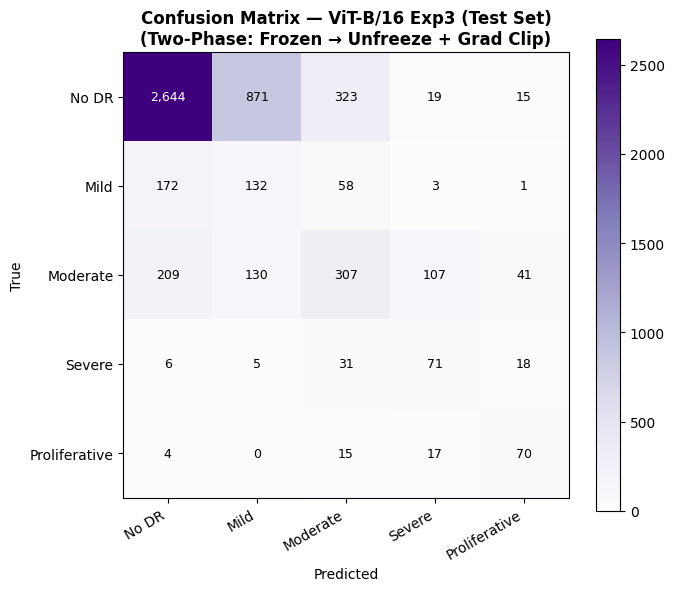

Saved → outputs/vit_b16_exp3/figures/vit_b16_exp3_confusion_matrix.png


In [44]:
cm_exp3 = confusion_matrix(exp3_y_true, exp3_y_pred)

fig, ax = plt.subplots(figsize=(7, 6))
im = ax.imshow(cm_exp3, interpolation='nearest', cmap='Purples')
fig.colorbar(im, ax=ax)
ax.set_xticks(range(NUM_CLASSES)); ax.set_xticklabels(CLASS_NAMES, rotation=30, ha='right')
ax.set_yticks(range(NUM_CLASSES)); ax.set_yticklabels(CLASS_NAMES)
ax.set_xlabel('Predicted'); ax.set_ylabel('True')
ax.set_title('Confusion Matrix — ViT-B/16 Exp3 (Test Set)\n(Two-Phase: Frozen → Unfreeze + Grad Clip)', fontweight='bold')

thresh = cm_exp3.max() / 2
for i in range(cm_exp3.shape[0]):
    for j in range(cm_exp3.shape[1]):
        ax.text(j, i, f'{cm_exp3[i, j]:,}', ha='center', va='center', fontsize=9,
                color='white' if cm_exp3[i, j] > thresh else 'black')

plt.tight_layout()
fig.savefig(EXP3_FIG_DIR / 'vit_b16_exp3_confusion_matrix.png', dpi=150, bbox_inches='tight')
plt.show()
print('Saved → outputs/vit_b16_exp3/figures/vit_b16_exp3_confusion_matrix.png')

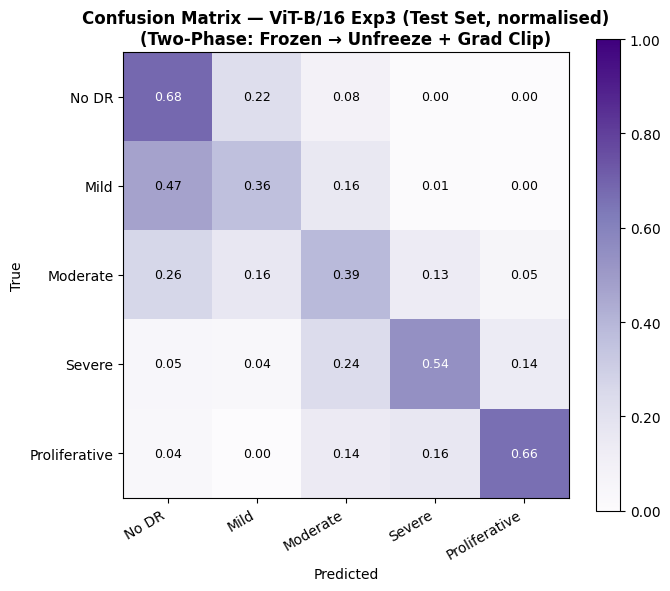

Saved → outputs/vit_b16_exp3/figures/vit_b16_exp3_confusion_matrix_normalised.png


In [45]:
cm_exp3_norm = cm_exp3.astype(float) / cm_exp3.sum(axis=1, keepdims=True)

fig, ax = plt.subplots(figsize=(7, 6))
im = ax.imshow(cm_exp3_norm, interpolation='nearest', cmap='Purples', vmin=0, vmax=1)
fig.colorbar(im, ax=ax, format='%.2f')
ax.set_xticks(range(NUM_CLASSES)); ax.set_xticklabels(CLASS_NAMES, rotation=30, ha='right')
ax.set_yticks(range(NUM_CLASSES)); ax.set_yticklabels(CLASS_NAMES)
ax.set_xlabel('Predicted'); ax.set_ylabel('True')
ax.set_title('Confusion Matrix — ViT-B/16 Exp3 (Test Set, normalised)\n(Two-Phase: Frozen → Unfreeze + Grad Clip)', fontweight='bold')

thresh = 0.5
for i in range(cm_exp3_norm.shape[0]):
    for j in range(cm_exp3_norm.shape[1]):
        ax.text(j, i, f'{cm_exp3_norm[i, j]:.2f}', ha='center', va='center', fontsize=9,
                color='white' if cm_exp3_norm[i, j] > thresh else 'black')

plt.tight_layout()
fig.savefig(EXP3_FIG_DIR / 'vit_b16_exp3_confusion_matrix_normalised.png', dpi=150, bbox_inches='tight')
plt.show()
print('Saved → outputs/vit_b16_exp3/figures/vit_b16_exp3_confusion_matrix_normalised.png')

In [79]:
exp3_qwk    = cohen_kappa_score(exp3_y_true, exp3_y_pred, weights='quadratic')
exp3_acc    = accuracy_score(exp3_y_true, exp3_y_pred)
exp3_f1_per = f1_score(exp3_y_true, exp3_y_pred, average=None, labels=list(range(5)))

W = 82
print('=' * W)
print(f'  {"Metric":<22} {"Baseline":>10}  {"Exp1 (WRS+FL)":>13}  {"Exp2 (+Aug)":>11}  {"Exp3 (2-Phase)":>14}')
print('=' * W)
for label, b, e1, e2, e3 in [
    ('Test QWK',      qwk, exp1_qwk, exp2_qwk, exp3_qwk),
    ('Test Accuracy', acc, exp1_acc, exp2_acc, exp3_acc),
]:
    print(f'  {label:<22} {b:>10.4f}  {e1:>13.4f}  {e2:>11.4f}  {e3:>14.4f}')
print()
print(f'  Per-class F1:')
for name, f1_b, f1_e1, f1_e2, f1_e3 in zip(CLASS_NAMES, f1_per, exp1_f1_per, exp2_f1_per, exp3_f1_per):
    print(f'    {name:<20}: {f1_b:.4f}  {f1_e1:.4f}  {f1_e2:.4f}  {f1_e3:.4f}')
print('=' * W)
print(f'  QWK delta vs Baseline:  Exp1={exp1_qwk-qwk:+.4f}  Exp2={exp2_qwk-qwk:+.4f}  Exp3={exp3_qwk-qwk:+.4f}')
print('=' * W)

  Metric                   Baseline  Exp1 (WRS+FL)  Exp2 (+Aug)  Exp3 (2-Phase)
  Test QWK                   0.0000         0.3480       0.5208          0.5968
  Test Accuracy              0.7349         0.4971       0.5511          0.6119

  Per-class F1:
    No DR               : 0.8472  0.6741  0.7109  0.7656
    Mild                : 0.0000  0.1036  0.1790  0.1755
    Moderate            : 0.0000  0.2656  0.3833  0.4018
    Severe              : 0.0000  0.2124  0.3275  0.4080
    Proliferative       : 0.0000  0.3277  0.5340  0.5578
  QWK delta vs Baseline:  Exp1=+0.3480  Exp2=+0.5208  Exp3=+0.5968


## 14. Experiment 4 — Hyperparameter Grid Search (LR × Batch Size × Weight Decay)

**Goal:** Identify the optimal learning rate, batch size, and weight decay before committing to full-length runs.  
Stochastic depth (`drop_path_rate`) is fixed at 0.1 — a safe default from the ViT paper that adds light regularisation to transformer blocks.

**Search space:**

| Hyperparameter | Values | Notes |
|---|---|---|
| Learning rate | 1e-4, 3e-4, 1e-3 | Cosine-decayed from epoch 1 |
| Batch size | 16, 32, 64 | Affects gradient noise and steps/epoch |
| Weight decay | 1e-3, 1e-2 | AdamW L2 penalty |
| `drop_path_rate` | **0.1 (fixed)** | Stochastic depth for transformer blocks |

**Protocol:** Each of the 18 combinations is trained for up to 5 epochs (early stopping patience=2)
using the Exp2 setup — FocalLoss (γ=2) + WeightedRandomSampler + enhanced augmentation.
Val loss selects the winner. No test-set access during search.

> **Expected runtime:** ~90–120 min.  
> **Dependencies:** Sections 11–12 must be run first (`exp2_train_ds`, `exp1_sampler`, `class_weights_t`, `FocalLoss`).

In [17]:
TUNE_LRS          = [1e-3, 3e-4, 1e-4, 5e-5, 3e-5]
TUNE_BATCH_SIZES  = [16, 32]
TUNE_WEIGHT_DECAYS = [1e-3, 1e-2]
TUNE_DROP_PATH    = 0.1   # stochastic depth — fixed across the search
TUNE_EPOCHS       = 5
TUNE_PATIENCE     = 3

n_combos = len(TUNE_LRS) * len(TUNE_BATCH_SIZES) * len(TUNE_WEIGHT_DECAYS)

EXP4_OUT_DIR  = ROOT / 'outputs' / 'vit_b16_exp4'
EXP4_CKPT_DIR = EXP4_OUT_DIR / 'checkpoints'
EXP4_FIG_DIR  = EXP4_OUT_DIR / 'figures'
for d in (EXP4_CKPT_DIR, EXP4_FIG_DIR):
    d.mkdir(parents=True, exist_ok=True)

print(f'Grid: {len(TUNE_LRS)} LRs × {len(TUNE_BATCH_SIZES)} BSes × {len(TUNE_WEIGHT_DECAYS)} WDs = {n_combos} combinations')
print(f'Max epochs per run : {TUNE_EPOCHS}  (early stop patience={TUNE_PATIENCE})')
print(f'drop_path_rate     : {TUNE_DROP_PATH} (fixed)')
print(f'Checkpoints        → {EXP4_CKPT_DIR}')

Grid: 5 LRs × 2 BSes × 2 WDs = 20 combinations
Max epochs per run : 5  (early stop patience=3)
drop_path_rate     : 0.1 (fixed)
Checkpoints        → /scratch/AML_G14_CW/outputs/vit_b16_exp4/checkpoints


In [20]:
tune_results = []
combo_num    = 0

print(f"{'#':<4} {'LR':>8} {'BS':>4} {'WD':>8}  {'Best Ep':>7} {'Val Loss':>10} {'Val Acc':>9}")
print('─' * 58)

for bs in TUNE_BATCH_SIZES:
    tune_train_loader_bs = DataLoader(
        exp2_train_ds, batch_size=bs, sampler=exp1_sampler,
        num_workers=NUM_WORKERS, pin_memory=True, drop_last=True,
        persistent_workers=NUM_WORKERS > 0,
    )
    tune_val_loader_bs = DataLoader(
        val_ds, batch_size=bs, shuffle=False,
        num_workers=NUM_WORKERS, pin_memory=True,
        persistent_workers=NUM_WORKERS > 0,
    )

    for wd in TUNE_WEIGHT_DECAYS:
        for lr in TUNE_LRS:
            combo_num += 1
            set_seed(SEED)

            tune_model = timm.create_model(
                MODEL_NAME, pretrained=True, num_classes=NUM_CLASSES,
                drop_path_rate=TUNE_DROP_PATH,
            ).to(device)
            tune_criterion = FocalLoss(alpha=class_weights_t, gamma=2.0)
            tune_optimizer = torch.optim.AdamW(tune_model.parameters(), lr=lr, weight_decay=wd)
            tune_scheduler = torch.optim.lr_scheduler.CosineAnnealingLR(tune_optimizer, T_max=TUNE_EPOCHS)
            tune_scaler    = torch.amp.GradScaler('cuda', enabled=use_amp)

            # Rebind free variables used by run_epoch
            _t_model, _t_crit, _t_opt, _t_sc = model, criterion, optimizer, scaler
            model, criterion, optimizer, scaler = tune_model, tune_criterion, tune_optimizer, tune_scaler

            best_loss     = float('inf')
            best_acc      = 0.0
            best_epoch    = 0
            tune_patience = TUNE_PATIENCE

            for epoch in range(1, TUNE_EPOCHS + 1):
                run_epoch(tune_train_loader_bs, train_mode=True)
                ep_loss, ep_labels, ep_preds = run_epoch(tune_val_loader_bs, train_mode=False)
                tune_scheduler.step()

                ep_acc = accuracy_score(ep_labels, ep_preds)
                if ep_loss < best_loss:
                    best_loss, best_acc, best_epoch = ep_loss, ep_acc, epoch
                    tune_patience = TUNE_PATIENCE
                    torch.save(
                        {'epoch': epoch, 'model_state': tune_model.state_dict(), 'val_loss': ep_loss},
                        EXP4_CKPT_DIR / f'tune_bs{bs}_lr{lr:.0e}_wd{wd:.0e}_best.pt',
                    )
                else:
                    tune_patience -= 1
                if tune_patience == 0:
                    break

            print(f'{combo_num:<4} {lr:>8.0e} {bs:>4} {wd:>8.0e}   ep={best_epoch:2d}    {best_loss:>10.4f}  {best_acc:>9.4f}')
            tune_results.append({
                'lr': lr, 'batch_size': bs, 'weight_decay': wd,
                'best_val_loss': best_loss, 'best_val_acc': best_acc,
                'stopped_at': best_epoch,
            })

            # Restore and free CUDA memory before next run
            model, criterion, optimizer, scaler = _t_model, _t_crit, _t_opt, _t_sc
            del tune_model
            torch.cuda.empty_cache()

print('\nGrid search complete.')

#          LR   BS       WD  Best Ep   Val Loss   Val Acc
──────────────────────────────────────────────────────────


train:   0%|          | 0/1536 [00:00<?, ?it/s]

val:   0%|          | 0/330 [00:00<?, ?it/s]

train:   0%|          | 0/1536 [00:00<?, ?it/s]

val:   0%|          | 0/330 [00:00<?, ?it/s]

...

train:   0%|          | 0/768 [00:00<?, ?it/s]

val:   0%|          | 0/165 [00:00<?, ?it/s]

train:   0%|          | 0/768 [00:00<?, ?it/s]

val:   0%|          | 0/165 [00:00<?, ?it/s]

20      3e-05   32    1e-02   ep= 1        1.0357     0.0991

Grid search complete.


Grid Search Results (ranked by val loss):

Rank         LR   BS       WD  Stop Ep   Val Loss   Val Acc
──────────────────────────────────────────────────────────────
1         3e-05   16    1e-03        2     0.9388    0.0985  ← BEST
2         5e-05   16    1e-03        2     0.9631    0.0934
3         3e-05   16    1e-02        2     0.9853    0.0962
4         3e-05   32    1e-02        1     1.0357    0.0991
5         5e-05   32    1e-02        2     1.0424    0.0928
6         1e-04   16    1e-03        2     1.0487    0.0869
7         5e-05   32    1e-03        2     1.0712    0.0955
8         3e-05   32    1e-03        2     1.0757    0.0941
9         5e-05   16    1e-02        2     1.0758    0.0888
10        1e-04   32    1e-03        3     1.1111    0.0864
11        1e-04   32    1e-02        2     1.1172    0.0858
12        1e-04   16    1e-02        2     1.1640    0.0791
13        3e-04   32    1e-02        2     1.1849    0.0803
14        3e-04   16    1e-02        5     1.2

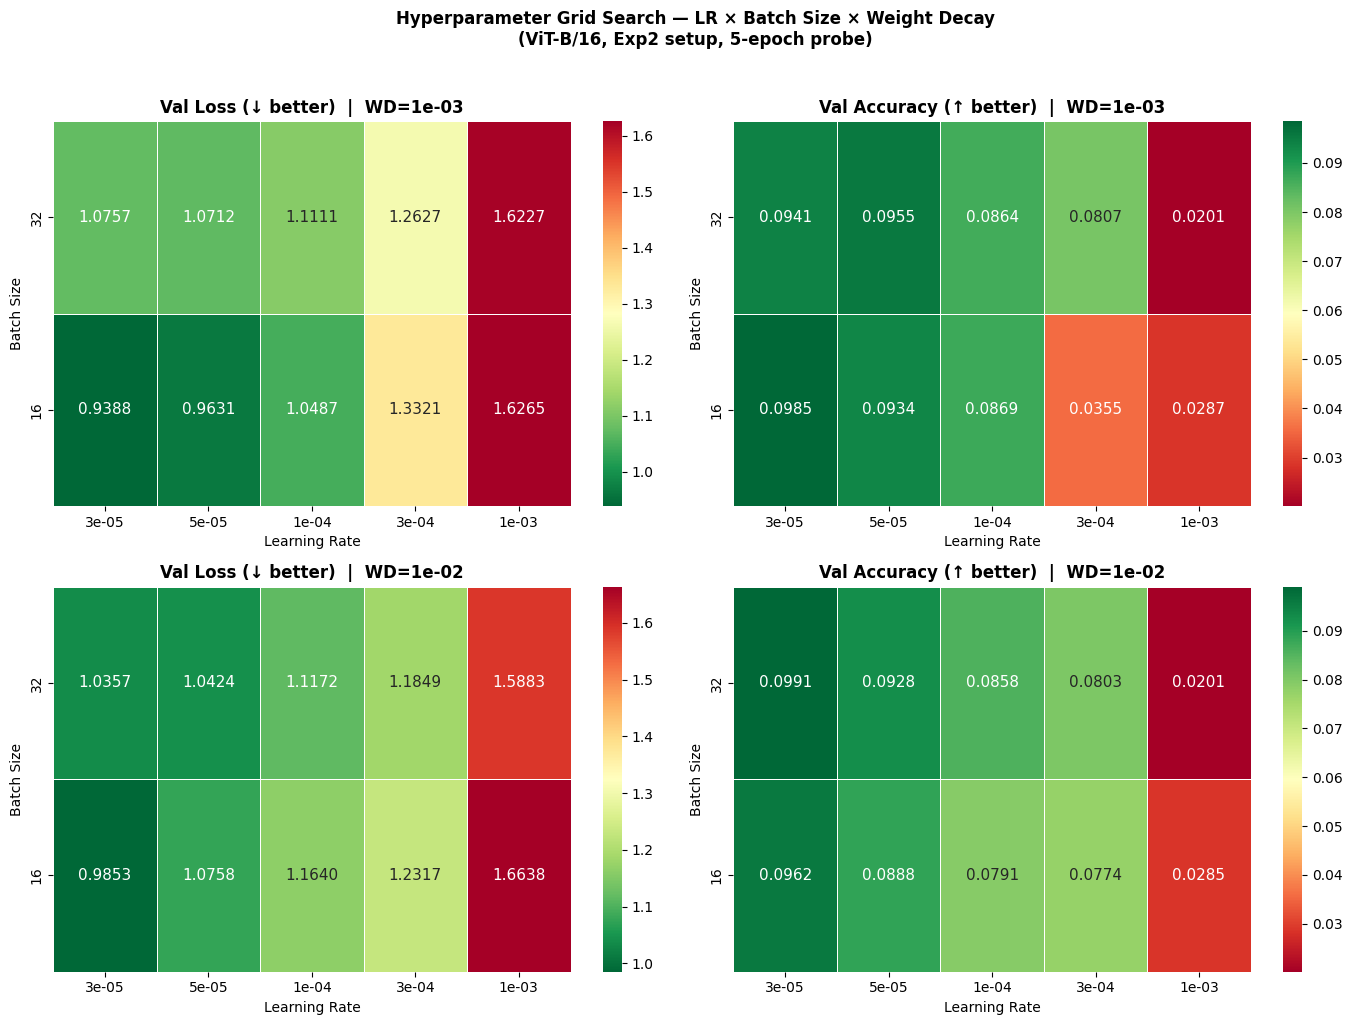

Saved → outputs/vit_b16_exp4/figures/vit_b16_exp4_hparam_heatmap.png

Use LR=3e-05, batch_size=16, weight_decay=1e-03 for subsequent full training runs.


In [21]:
import seaborn as sns

tune_df = pd.DataFrame(tune_results).sort_values('best_val_loss').reset_index(drop=True)

# ── Ranked results table ───────────────────────────────────────────────────────
print('Grid Search Results (ranked by val loss):')
print(f"\n{'Rank':<6} {'LR':>8} {'BS':>4} {'WD':>8} {'Stop Ep':>8} {'Val Loss':>10} {'Val Acc':>9}")
print('─' * 62)
for rank, row in tune_df.iterrows():
    marker = '  ← BEST' if rank == 0 else ''
    print(f'{rank+1:<6} {row["lr"]:>8.0e} {int(row["batch_size"]):>4} '
          f'{row["weight_decay"]:>8.0e} {int(row["stopped_at"]):>8} '
          f'{row["best_val_loss"]:>10.4f} {row["best_val_acc"]:>9.4f}{marker}')

best_row = tune_df.iloc[0]
best_lr  = best_row['lr']
best_bs  = int(best_row['batch_size'])
best_wd  = best_row['weight_decay']
print(f'\n→ Best config: LR={best_lr:.0e}  Batch size={best_bs}  Weight decay={best_wd:.0e}')
print(  f'  Val loss={best_row["best_val_loss"]:.4f}  Val acc={best_row["best_val_acc"]:.4f}')

# ── Heatmaps — (rows = weight_decay, cols = val loss / val accuracy) ──────────
wd_values = sorted(tune_df['weight_decay'].unique())
fig, axes = plt.subplots(len(wd_values), 2, figsize=(14, 5 * len(wd_values)))

for row_idx, wd in enumerate(wd_values):
    subset     = tune_df[tune_df['weight_decay'] == wd]
    pivot_loss = (subset.pivot(index='batch_size', columns='lr', values='best_val_loss')
                        .sort_index(ascending=False))
    pivot_acc  = (subset.pivot(index='batch_size', columns='lr', values='best_val_acc')
                        .sort_index(ascending=False))

    for col_idx, (data, title, cmap) in enumerate([
        (pivot_loss, f'Val Loss (↓ better)  |  WD={wd:.0e}',     'RdYlGn_r'),
        (pivot_acc,  f'Val Accuracy (↑ better)  |  WD={wd:.0e}', 'RdYlGn'),
    ]):
        ax = axes[row_idx][col_idx]
        sns.heatmap(data, annot=True, fmt='.4f', cmap=cmap, ax=ax,
                    linewidths=0.5, annot_kws={'size': 11})
        ax.set_title(title, fontweight='bold')
        ax.set_xlabel('Learning Rate')
        ax.set_ylabel('Batch Size')
        ax.set_xticklabels([f'{float(c):.0e}' for c in data.columns])

plt.suptitle('Hyperparameter Grid Search — LR × Batch Size × Weight Decay\n(ViT-B/16, Exp2 setup, 5-epoch probe)',
             fontweight='bold', y=1.02)
plt.tight_layout()
fig.savefig(EXP4_FIG_DIR / 'vit_b16_exp4_hparam_heatmap.png', dpi=150, bbox_inches='tight')
plt.show()
print('Saved → outputs/vit_b16_exp4/figures/vit_b16_exp4_hparam_heatmap.png')
print(f'\nUse LR={best_lr:.0e}, batch_size={best_bs}, weight_decay={best_wd:.0e} for subsequent full training runs.')


## 15. Experiment 5 — Majority-Class Downsampling

**Hypothesis:** Grade 0 (No DR) accounts for ~73.5% of the training set, overwhelming the model
with easy negatives. Simply removing the excess — capping Grade 0 at the size of the next-largest
class (Grade 2) — should break the dominant imbalance while preserving every rare-grade sample.

**Design:** This experiment deliberately uses standard `CrossEntropyLoss` with no sampler or
class weights, so the result isolates the effect of data-level rebalancing alone.

| Class | Original count | Exp 5 count |
|---|---|---|
| Grade 0 — No DR | ~20,580 | capped to Grade 2 count |
| Grade 1 — Mild | ~1,960 | unchanged |
| Grade 2 — Moderate | ~4,200 | unchanged |
| Grade 3 — Severe | ~700 | unchanged |
| Grade 4 — Proliferative | ~560 | unchanged |

**Comparison point vs Exp 1:** Both target the same imbalance problem; Exp 1 keeps all data but
reweights via `WeightedRandomSampler` + `FocalLoss`, while Exp 5 removes the excess at source
and lets the balanced distribution do the work.

> **Dependencies:** Sections 1–10 must be run first (`train_df`, `DRDataset`, `train_transform`, `val_loader`, `test_loader`).

In [80]:
# ── Cap Grade 0 at Grade 2's count ───────────────────────────────────────────
grade2_count  = (train_df['level'] == 2).sum()
grade0_capped = (train_df[train_df['level'] == 0]
                 .sample(n=grade2_count, random_state=SEED))
exp5_train_df = (pd.concat([grade0_capped, train_df[train_df['level'] != 0]])
                 .sample(frac=1, random_state=SEED)
                 .reset_index(drop=True))

print(f'Original training set : {len(train_df):,} images')
print(f'Exp5 training set     : {len(exp5_train_df):,} images')
print(f'\nGrade 0 cap target    : {grade2_count:,}  (= Grade 2 count)\n')
print(f'{"Grade":<6} {"Name":<18} {"Original":>10} {"Exp 5":>8}')
print('-' * 46)
for g, name in enumerate(CLASS_NAMES):
    orig = (train_df['level'] == g).sum()
    new  = (exp5_train_df['level'] == g).sum()
    note = '  ← capped' if g == 0 else ''
    print(f'  {g}    {name:<18} {orig:>9,}  {new:>7,}{note}')

exp5_train_ds = DRDataset(exp5_train_df, TRAIN_DIR, transform=train_transform)
exp5_train_loader = DataLoader(
    exp5_train_ds,
    batch_size=BATCH_SIZE,
    shuffle=True,
    num_workers=NUM_WORKERS,
    pin_memory=True,
    drop_last=True,
    persistent_workers=NUM_WORKERS > 0,
)
print(f'\nExp5 train loader: {len(exp5_train_loader)} batches/epoch')


Original training set : 24,588 images
Exp5 training set     : 10,225 images

Grade 0 cap target    : 3,704  (= Grade 2 count)

Grade  Name                 Original    Exp 5
----------------------------------------------
  0    No DR                 18,067    3,704  ← capped
  1    Mild                   1,710    1,710
  2    Moderate               3,704    3,704
  3    Severe                   611      611
  4    Proliferative            496      496

Exp5 train loader: 639 batches/epoch


In [81]:
set_seed(SEED)
exp5_model     = timm.create_model(MODEL_NAME, pretrained=True, num_classes=NUM_CLASSES).to(device)
exp5_criterion = nn.CrossEntropyLoss()
exp5_optimizer = torch.optim.AdamW(exp5_model.parameters(), lr=LR, weight_decay=WEIGHT_DECAY)
exp5_scheduler = torch.optim.lr_scheduler.CosineAnnealingLR(exp5_optimizer, T_max=EPOCHS)
exp5_scaler    = torch.amp.GradScaler('cuda', enabled=use_amp)

EXP5_OUT_DIR  = ROOT / 'outputs' / 'vit_b16_exp5'
EXP5_CKPT_DIR = EXP5_OUT_DIR / 'checkpoints'
EXP5_FIG_DIR  = EXP5_OUT_DIR / 'figures'
for d in (EXP5_CKPT_DIR, EXP5_FIG_DIR):
    d.mkdir(parents=True, exist_ok=True)

EXP5_BEST_PATH = EXP5_CKPT_DIR / 'vit_b16_exp5_best.pt'

print('Exp5 model ready.')
print('Loss      : CrossEntropyLoss (no class weights — downsampling provides the balance)')
print(f'Optimiser : AdamW  lr={LR}  wd={WEIGHT_DECAY}')
print(f'Checkpts  → {EXP5_CKPT_DIR}')
print(f'Figures   → {EXP5_FIG_DIR}')


Exp5 model ready.
Loss      : CrossEntropyLoss (no class weights — downsampling provides the balance)
Optimiser : AdamW  lr=0.0001  wd=0.01
Checkpts  → /scratch/AML_G14_CW/outputs/vit_b16_exp5/checkpoints
Figures   → /scratch/AML_G14_CW/outputs/vit_b16_exp5/figures


In [49]:
_e5_baseline_model     = globals().get('model',     None)
_e5_baseline_criterion = globals().get('criterion', None)
_e5_baseline_optimizer = globals().get('optimizer', None)
_e5_baseline_scaler    = globals().get('scaler',    None)

model, criterion, optimizer, scaler = exp5_model, exp5_criterion, exp5_optimizer, exp5_scaler

exp5_history       = {'train_loss': [], 'val_loss': [], 'train_acc': [], 'val_acc': []}
exp5_best_val_loss = float('inf')
exp5_patience_left = EARLY_STOPPING_PATIENCE

print(f"{'Epoch':<8} {'Tr Loss':>10} {'Tr Acc':>8} {'Val Loss':>10} {'Val Acc':>8}")
print('─' * 50)

for epoch in range(1, EPOCHS + 1):
    tr_loss, tr_labels, tr_preds = run_epoch(exp5_train_loader, train_mode=True)
    vl_loss, vl_labels, vl_preds = run_epoch(val_loader,        train_mode=False)
    exp5_scheduler.step()

    tr_acc = accuracy_score(tr_labels, tr_preds)
    vl_acc = accuracy_score(vl_labels, vl_preds)

    exp5_history['train_loss'].append(tr_loss)
    exp5_history['val_loss'].append(vl_loss)
    exp5_history['train_acc'].append(tr_acc)
    exp5_history['val_acc'].append(vl_acc)

    marker = ''
    if vl_loss < exp5_best_val_loss:
        exp5_best_val_loss = vl_loss
        exp5_patience_left = EARLY_STOPPING_PATIENCE
        torch.save({'epoch': epoch, 'model_state': model.state_dict(),
                    'val_loss': vl_loss}, EXP5_BEST_PATH)
        marker = '  ← best'
    else:
        exp5_patience_left -= 1

    print(f'{epoch:<8} {tr_loss:>10.4f} {tr_acc:>8.4f} {vl_loss:>10.4f} {vl_acc:>8.4f}{marker}')

    if exp5_patience_left == 0:
        print(f'\nEarly stopping at epoch {epoch}.')
        break

print(f'\nBest val loss: {exp5_best_val_loss:.4f}  →  {EXP5_BEST_PATH}')

if _e5_baseline_model is not None:
    model, criterion, optimizer, scaler = (
        _e5_baseline_model, _e5_baseline_criterion,
        _e5_baseline_optimizer, _e5_baseline_scaler
    )


Epoch       Tr Loss   Tr Acc   Val Loss  Val Acc
──────────────────────────────────────────────────


train:   0%|          | 0/639 [00:00<?, ?it/s]

val:   0%|          | 0/330 [00:00<?, ?it/s]

1            1.2035   0.4758     1.0376   0.5443  ← best


train:   0%|          | 0/639 [00:00<?, ?it/s]

...

val:   0%|          | 0/330 [00:00<?, ?it/s]

9            0.6862   0.7165     1.0773   0.5973


train:   0%|          | 0/639 [00:00<?, ?it/s]

val:   0%|          | 0/330 [00:00<?, ?it/s]

10           0.6008   0.7553     0.9548   0.6316

Early stopping at epoch 10.

Best val loss: 0.7503  →  /scratch/AML_G14_CW/outputs/vit_b16_exp5/checkpoints/vit_b16_exp5_best.pt


Epoch       Tr Loss   Tr Acc   Val Loss  Val Acc
──────────────────────────────────────────────────
1            1.2035   0.4758     1.0376   0.5443
2            1.0512   0.5489     1.1417   0.4646
3            1.0029   0.5725     0.8398   0.7360
4            0.9653   0.5883     0.7960   0.7565
5            0.9221   0.6150     0.7503   0.7540
6            0.8759   0.6338     0.7887   0.7400
7            0.8288   0.6509     0.8946   0.6561
8            0.7614   0.6793     0.7731   0.7309
9            0.6862   0.7165     1.0773   0.5973
10           0.6008   0.7553     0.9548   0.6316



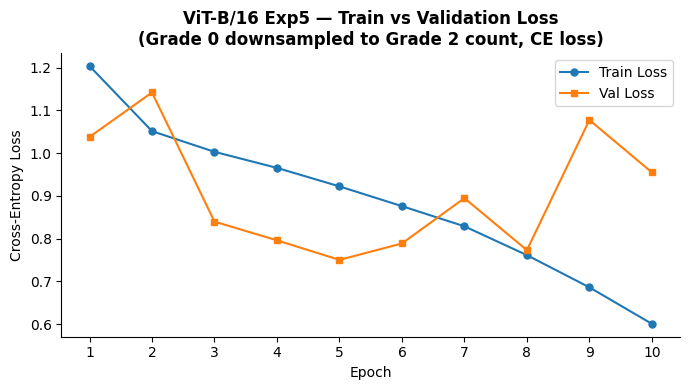

Saved → outputs/vit_b16_exp5/figures/vit_b16_exp5_loss_curve.png


In [50]:
epochs_ran_exp5 = range(1, len(exp5_history['train_loss']) + 1)

print(f"{'Epoch':<8} {'Tr Loss':>10} {'Tr Acc':>8} {'Val Loss':>10} {'Val Acc':>8}")
print('─' * 50)
for ep, (tl, ta, vl, va) in enumerate(
    zip(exp5_history['train_loss'], exp5_history['train_acc'],
        exp5_history['val_loss'],   exp5_history['val_acc']), 1
):
    print(f'{ep:<8} {tl:>10.4f} {ta:>8.4f} {vl:>10.4f} {va:>8.4f}')
print()

fig, ax = plt.subplots(figsize=(7, 4))
ax.plot(epochs_ran_exp5, exp5_history['train_loss'], label='Train Loss', marker='o', markersize=5)
ax.plot(epochs_ran_exp5, exp5_history['val_loss'],   label='Val Loss',   marker='s', markersize=5)
ax.set_title('ViT-B/16 Exp5 — Train vs Validation Loss\n(Grade 0 downsampled to Grade 2 count, CE loss)', fontweight='bold')
ax.set_xlabel('Epoch'); ax.set_ylabel('Cross-Entropy Loss')
ax.xaxis.set_major_locator(ticker.MaxNLocator(integer=True))
ax.legend(); ax.spines[['top', 'right']].set_visible(False)
plt.tight_layout()
fig.savefig(EXP5_FIG_DIR / 'vit_b16_exp5_loss_curve.png', dpi=150, bbox_inches='tight')
plt.show()
print('Saved → outputs/vit_b16_exp5/figures/vit_b16_exp5_loss_curve.png')


In [82]:
# ── Independent of training cell — requires Sections 1–7 + checkpoint registry ─
_prev_model     = globals().get('model',     None)
_prev_criterion = globals().get('criterion', None)

model     = timm.create_model(MODEL_NAME, pretrained=False, num_classes=NUM_CLASSES).to(device)
criterion = nn.CrossEntropyLoss()

ckpt = torch.load(CKPT_EXP5, map_location=device, weights_only=False)
model.load_state_dict(ckpt['model_state'])
print(f'Exp5: loaded {CKPT_EXP5.name}  (epoch {ckpt["epoch"]}, val_loss={ckpt["val_loss"]:.4f})')

_, exp5_y_true, exp5_y_pred = run_epoch(test_loader, train_mode=False)

print('\nExp5 Classification Report (Test Set):')
print(classification_report(exp5_y_true, exp5_y_pred, target_names=CLASS_NAMES, digits=3))

if _prev_model is not None:
    model     = _prev_model
    criterion = _prev_criterion


Exp5: loaded vit_b16_exp5_best.pt  (epoch 5, val_loss=0.7503)


val:   0%|          | 0/330 [00:00<?, ?it/s]


Exp5 Classification Report (Test Set):
               precision    recall  f1-score   support

        No DR      0.847     0.895     0.870      3872
         Mild      0.000     0.000     0.000       366
     Moderate      0.440     0.563     0.494       794
       Severe      0.540     0.260     0.351       131
Proliferative      0.649     0.594     0.621       106

     accuracy                          0.761      5269
    macro avg      0.495     0.462     0.467      5269
 weighted avg      0.715     0.761     0.735      5269



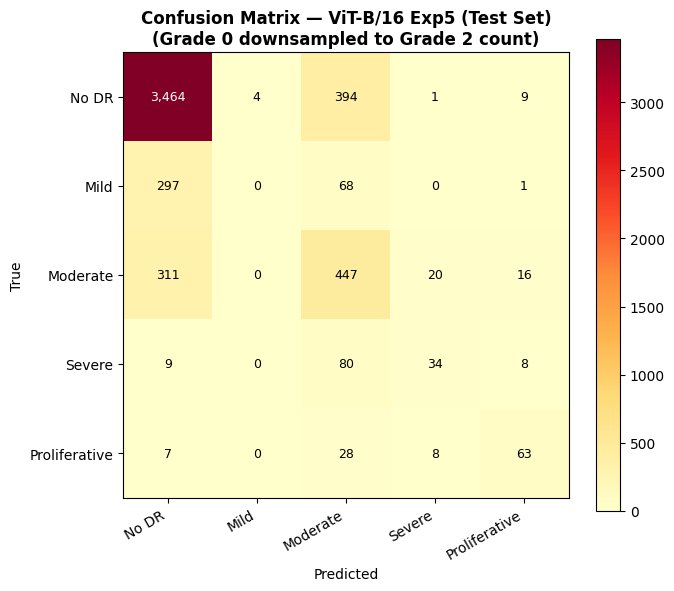

Saved → outputs/vit_b16_exp5/figures/vit_b16_exp5_confusion_matrix.png


In [52]:
cm_exp5 = confusion_matrix(exp5_y_true, exp5_y_pred)

fig, ax = plt.subplots(figsize=(7, 6))
im = ax.imshow(cm_exp5, interpolation='nearest', cmap='YlOrRd')
fig.colorbar(im, ax=ax)
ax.set_xticks(range(NUM_CLASSES)); ax.set_xticklabels(CLASS_NAMES, rotation=30, ha='right')
ax.set_yticks(range(NUM_CLASSES)); ax.set_yticklabels(CLASS_NAMES)
ax.set_xlabel('Predicted'); ax.set_ylabel('True')
ax.set_title('Confusion Matrix — ViT-B/16 Exp5 (Test Set)\n(Grade 0 downsampled to Grade 2 count)', fontweight='bold')

thresh = cm_exp5.max() / 2
for i in range(cm_exp5.shape[0]):
    for j in range(cm_exp5.shape[1]):
        ax.text(j, i, f'{cm_exp5[i, j]:,}', ha='center', va='center', fontsize=9,
                color='white' if cm_exp5[i, j] > thresh else 'black')

plt.tight_layout()
fig.savefig(EXP5_FIG_DIR / 'vit_b16_exp5_confusion_matrix.png', dpi=150, bbox_inches='tight')
plt.show()
print('Saved → outputs/vit_b16_exp5/figures/vit_b16_exp5_confusion_matrix.png')


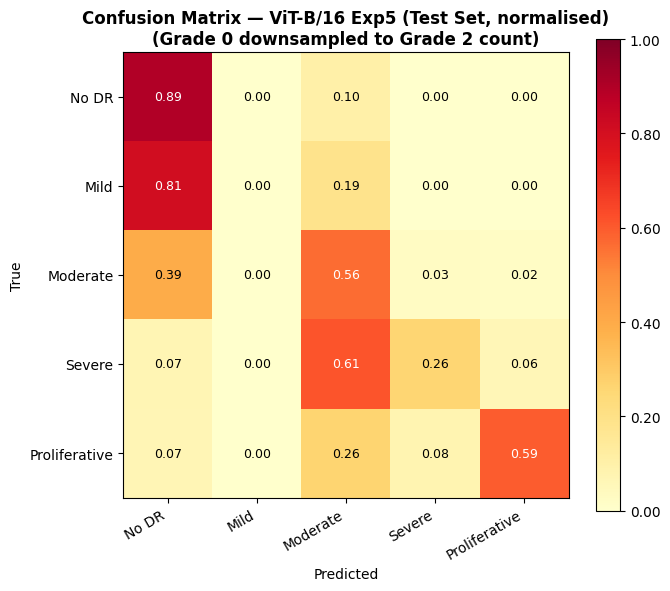

Saved → outputs/vit_b16_exp5/figures/vit_b16_exp5_confusion_matrix_normalised.png


In [53]:
cm_exp5_norm = cm_exp5.astype(float) / cm_exp5.sum(axis=1, keepdims=True)

fig, ax = plt.subplots(figsize=(7, 6))
im = ax.imshow(cm_exp5_norm, interpolation='nearest', cmap='YlOrRd', vmin=0, vmax=1)
fig.colorbar(im, ax=ax, format='%.2f')
ax.set_xticks(range(NUM_CLASSES)); ax.set_xticklabels(CLASS_NAMES, rotation=30, ha='right')
ax.set_yticks(range(NUM_CLASSES)); ax.set_yticklabels(CLASS_NAMES)
ax.set_xlabel('Predicted'); ax.set_ylabel('True')
ax.set_title('Confusion Matrix — ViT-B/16 Exp5 (Test Set, normalised)\n(Grade 0 downsampled to Grade 2 count)', fontweight='bold')

thresh = 0.5
for i in range(cm_exp5_norm.shape[0]):
    for j in range(cm_exp5_norm.shape[1]):
        ax.text(j, i, f'{cm_exp5_norm[i, j]:.2f}', ha='center', va='center', fontsize=9,
                color='white' if cm_exp5_norm[i, j] > thresh else 'black')

plt.tight_layout()
fig.savefig(EXP5_FIG_DIR / 'vit_b16_exp5_confusion_matrix_normalised.png', dpi=150, bbox_inches='tight')
plt.show()
print('Saved → outputs/vit_b16_exp5/figures/vit_b16_exp5_confusion_matrix_normalised.png')


In [83]:
exp5_qwk    = cohen_kappa_score(exp5_y_true, exp5_y_pred, weights='quadratic')
exp5_acc    = accuracy_score(exp5_y_true, exp5_y_pred)
exp5_f1_per = f1_score(exp5_y_true, exp5_y_pred, average=None, labels=list(range(5)))

W = 96
print('=' * W)
print(f'  {"Metric":<22} {"Baseline":>10}  {"Exp1 (WRS+FL)":>13}  {"Exp2 (+Aug)":>11}  {"Exp3 (2-Phase)":>14}  {"Exp5 (Downsample)":>17}')
print('=' * W)
for label, b, e1, e2, e3, e5 in [
    ('Test QWK',      qwk,  exp1_qwk, exp2_qwk, exp3_qwk, exp5_qwk),
    ('Test Accuracy', acc,  exp1_acc, exp2_acc, exp3_acc, exp5_acc),
]:
    print(f'  {label:<22} {b:>10.4f}  {e1:>13.4f}  {e2:>11.4f}  {e3:>14.4f}  {e5:>17.4f}')
print()
print(f'  Per-class F1:')
for name, f1_b, f1_e1, f1_e2, f1_e3, f1_e5 in zip(CLASS_NAMES, f1_per, exp1_f1_per, exp2_f1_per, exp3_f1_per, exp5_f1_per):
    print(f'    {name:<20}: {f1_b:.4f}  {f1_e1:.4f}  {f1_e2:.4f}  {f1_e3:.4f}  {f1_e5:.4f}')
print('=' * W)
print(f'  QWK delta vs Baseline:  Exp1={exp1_qwk-qwk:+.4f}  Exp2={exp2_qwk-qwk:+.4f}  Exp3={exp3_qwk-qwk:+.4f}  Exp5={exp5_qwk-qwk:+.4f}')
print('=' * W)


  Metric                   Baseline  Exp1 (WRS+FL)  Exp2 (+Aug)  Exp3 (2-Phase)  Exp5 (Downsample)
  Test QWK                   0.0000         0.3480       0.5208          0.5968             0.6109
  Test Accuracy              0.7349         0.4971       0.5511          0.6119             0.7607

  Per-class F1:
    No DR               : 0.8472  0.6741  0.7109  0.7656  0.8704
    Mild                : 0.0000  0.1036  0.1790  0.1755  0.0000
    Moderate            : 0.0000  0.2656  0.3833  0.4018  0.4936
    Severe              : 0.0000  0.2124  0.3275  0.4080  0.3505
    Proliferative       : 0.0000  0.3277  0.5340  0.5578  0.6207
  QWK delta vs Baseline:  Exp1=+0.3480  Exp2=+0.5208  Exp3=+0.5968  Exp5=+0.6109


## 16. Experiment 6 — Two-Phase Training + Smart Downsampling

**Hypothesis:** Combining Exp3's two-phase fine-tuning with smarter data-level rebalancing should outperform either technique alone. Exp3 trained on the full imbalanced dataset (Grade 0 = 73.5%) relying on WRS + FocalLoss to compensate at training time. Exp5 rebalanced the data but used plain CE and single-phase training. Exp6 does both: cap the dominant classes to give a balanced training set, then apply two-phase fine-tuning with FocalLoss(γ=2) for the remaining hard examples.

**Design:**

| Component | Choice | Rationale |
|---|---|---|
| **Dataset** | All classes capped at `DOWNSAMPLE_CAP` (≈ Grade 1 count) | Removes Grade 0 and Grade 2 excess |
| **Sampler** | Standard shuffle (no WRS) | Downsampling already balances Grades 0–2 |
| **Loss** | `FocalLoss(alpha=None, γ=2)` | Hard-example focusing; no alpha double-correction |
| **Phase 1** | Frozen backbone (head only, LR=3e-4) | Stabilises the 5-class head first |
| **Phase 2** | Full fine-tune (LR=1e-5, lower than Exp3) | Conservative unfreezing — Exp3 peaked at epoch 2/5 |
| **Augmentation** | Exp2's enhanced set | HFlip + VFlip + Rotation + ColorJitter + RandomAffine |

**All HP constants are named variables** — edit the setup cell and re-run to log a new row to the CSV.

> **Dependencies:** Sections 1–13 (`run_epoch_clipped`, `exp2_train_transform`, `test_loader`,
> `FocalLoss`) and the checkpoint registry cell.

In [84]:
# ── Hyperparameter constants — edit here before each run ─────────────────────
EXP6_PHASE1_EPOCHS = 20
EXP6_PHASE2_EPOCHS = 20
EXP6_PHASE1_LR     = 3e-4
EXP6_PHASE2_LR     = 1e-5
EXP6_BATCH_SIZE    = 16
EXP6_WEIGHT_DECAY  = 1e-2
EXP6_GRAD_CLIP     = 1.0
EXP6_PATIENCE      = 5
DOWNSAMPLE_CAP     = int((train_df['level'] == 1).sum())   # cap = Grade 1 count

# ── Smart downsampling — cap every class at DOWNSAMPLE_CAP ───────────────────
parts = []
for grade in range(NUM_CLASSES):
    cls_df = train_df[train_df['level'] == grade]
    cap    = min(len(cls_df), DOWNSAMPLE_CAP)
    parts.append(cls_df.sample(n=cap, random_state=SEED))

exp6_train_df = (pd.concat(parts)
                 .sample(frac=1, random_state=SEED)
                 .reset_index(drop=True))

print(f'Original training set : {len(train_df):,} images')
print(f'Exp6 training set     : {len(exp6_train_df):,} images  (cap={DOWNSAMPLE_CAP:,})\n')
print(f'{"Grade":<6} {"Name":<18} {"Original":>10} {"Exp 6":>8}')
print('-' * 46)
for g, name in enumerate(CLASS_NAMES):
    orig = (train_df['level'] == g).sum()
    new  = (exp6_train_df['level'] == g).sum()
    note = '  ← capped' if orig > DOWNSAMPLE_CAP else ''
    print(f'  {g}    {name:<18} {orig:>9,}  {new:>7,}{note}')

exp6_train_ds = DRDataset(exp6_train_df, TRAIN_DIR, transform=exp2_train_transform)
exp6_train_loader = DataLoader(
    exp6_train_ds,
    batch_size=EXP6_BATCH_SIZE,
    shuffle=True,
    num_workers=NUM_WORKERS,
    pin_memory=True,
    drop_last=True,
    persistent_workers=NUM_WORKERS > 0,
)
print(f'\nExp6 train loader: {len(exp6_train_loader)} batches/epoch  (BS={EXP6_BATCH_SIZE})')


Original training set : 24,588 images
Exp6 training set     : 6,237 images  (cap=1,710)

Grade  Name                 Original    Exp 6
----------------------------------------------
  0    No DR                 18,067    1,710  ← capped
  1    Mild                   1,710    1,710
  2    Moderate               3,704    1,710  ← capped
  3    Severe                   611      611
  4    Proliferative            496      496

Exp6 train loader: 389 batches/epoch  (BS=16)


In [85]:
set_seed(SEED)
exp6_model     = timm.create_model(MODEL_NAME, pretrained=True, num_classes=NUM_CLASSES).to(device)
exp6_criterion = FocalLoss(alpha=None, gamma=2.0)
exp6_scaler    = torch.amp.GradScaler('cuda', enabled=use_amp)

EXP6_OUT_DIR  = ROOT / 'outputs' / 'vit_b16_exp6'
EXP6_CKPT_DIR = EXP6_OUT_DIR / 'checkpoints'
EXP6_FIG_DIR  = EXP6_OUT_DIR / 'figures'
for d in (EXP6_CKPT_DIR, EXP6_FIG_DIR):
    d.mkdir(parents=True, exist_ok=True)

print('Exp6 model ready.')
print(f'Loss        : FocalLoss(alpha=None, gamma=2.0)')
print(f'Phase 1     : LR={EXP6_PHASE1_LR:.0e}  {EXP6_PHASE1_EPOCHS} epochs  grad_clip={EXP6_GRAD_CLIP}')
print(f'Phase 2     : LR={EXP6_PHASE2_LR:.0e}  {EXP6_PHASE2_EPOCHS} epochs  patience={EXP6_PATIENCE}')
print(f'Batch size  : {EXP6_BATCH_SIZE}  weight_decay={EXP6_WEIGHT_DECAY}')
print(f'Checkpoints → {EXP6_CKPT_DIR}')


Exp6 model ready.
Loss        : FocalLoss(alpha=None, gamma=2.0)
Phase 1     : LR=3e-04  20 epochs  grad_clip=1.0
Phase 2     : LR=1e-05  20 epochs  patience=5
Batch size  : 16  weight_decay=0.01
Checkpoints → /scratch/AML_G14_CW/outputs/vit_b16_exp6/checkpoints


In [86]:
# ── Freeze backbone ──────────────────────────────────────────────────────────
for name, param in exp6_model.named_parameters():
    if 'head' not in name:
        param.requires_grad = False

trainable_p1 = sum(p.numel() for p in exp6_model.parameters() if p.requires_grad)
print(f'Phase 1: {trainable_p1:,} trainable parameters (head only)\n')

_e6_prev_model     = globals().get('model',     None)
_e6_prev_criterion = globals().get('criterion', None)
_e6_prev_optimizer = globals().get('optimizer', None)
_e6_prev_scaler    = globals().get('scaler',    None)

model     = exp6_model
criterion = exp6_criterion
optimizer = torch.optim.AdamW(
    filter(lambda p: p.requires_grad, model.parameters()),
    lr=EXP6_PHASE1_LR, weight_decay=EXP6_WEIGHT_DECAY,
)
scaler       = exp6_scaler
scheduler_p1 = torch.optim.lr_scheduler.CosineAnnealingLR(optimizer, T_max=EXP6_PHASE1_EPOCHS)

exp6_history = {
    'phase1_train': [], 'phase1_val': [], 'phase1_train_acc': [], 'phase1_val_acc': [],
    'phase2_train': [], 'phase2_val': [], 'phase2_train_acc': [], 'phase2_val_acc': [],
}
p1_best_val        = float('inf')
p1_patience_left   = EXP6_PATIENCE
exp6_p1_best_epoch = 0
exp6_p1_best_val   = float('inf')

print(f"{"Epoch":<8} {"Tr Loss":>10} {"Tr Acc":>8} {"Val Loss":>10} {"Val Acc":>8}")
print('─' * 50)

for epoch in range(1, EXP6_PHASE1_EPOCHS + 1):
    tr_loss, tr_labels, tr_preds = run_epoch_clipped(exp6_train_loader, train_mode=True,  grad_clip=EXP6_GRAD_CLIP)
    vl_loss, vl_labels, vl_preds = run_epoch_clipped(val_loader,        train_mode=False)
    scheduler_p1.step()

    tr_acc = accuracy_score(tr_labels, tr_preds)
    vl_acc = accuracy_score(vl_labels, vl_preds)

    exp6_history['phase1_train'].append(tr_loss)
    exp6_history['phase1_val'].append(vl_loss)
    exp6_history['phase1_train_acc'].append(tr_acc)
    exp6_history['phase1_val_acc'].append(vl_acc)

    marker = ''
    if vl_loss < p1_best_val:
        p1_best_val        = vl_loss
        p1_patience_left   = EXP6_PATIENCE
        exp6_p1_best_epoch = epoch
        exp6_p1_best_val   = vl_loss
        torch.save({'epoch': epoch, 'model_state': model.state_dict(),
                    'val_loss': vl_loss}, CKPT_EXP6_P1)
        marker = '  ← best'
    else:
        p1_patience_left -= 1

    print(f'{epoch:<8} {tr_loss:>10.4f} {tr_acc:>8.4f} {vl_loss:>10.4f} {vl_acc:>8.4f}{marker}')

    if p1_patience_left == 0:
        print(f'\nEarly stopping at epoch {epoch}.')
        break

print(f'\nPhase 1 complete. Best val loss: {p1_best_val:.4f}  (epoch {exp6_p1_best_epoch})')


Phase 1: 3,845 trainable parameters (head only)

Epoch       Tr Loss   Tr Acc   Val Loss  Val Acc
──────────────────────────────────────────────────


train:   0%|          | 0/389 [00:00<?, ?it/s]

eval:   0%|          | 0/330 [00:00<?, ?it/s]

1            0.9040   0.3344     0.4695   0.6352  ← best


train:   0%|          | 0/389 [00:00<?, ?it/s]

...

eval:   0%|          | 0/330 [00:00<?, ?it/s]

6            0.6595   0.4470     0.5473   0.5045


train:   0%|          | 0/389 [00:00<?, ?it/s]

eval:   0%|          | 0/330 [00:00<?, ?it/s]

7            0.6548   0.4512     0.5706   0.5067

Early stopping at epoch 7.

Phase 1 complete. Best val loss: 0.4224  (epoch 2)


In [87]:
# ── Unfreeze all parameters ──────────────────────────────────────────────────
for param in exp6_model.parameters():
    param.requires_grad = True

trainable_p2 = sum(p.numel() for p in exp6_model.parameters() if p.requires_grad)
print(f'Phase 2: {trainable_p2:,} trainable parameters (all layers)\n')

ckpt_p1 = torch.load(CKPT_EXP6_P1, map_location=device, weights_only=False)
model.load_state_dict(ckpt_p1['model_state'])
print(f'Loaded Phase 1 best (epoch {ckpt_p1["epoch"]}, val_loss={ckpt_p1["val_loss"]:.4f})')

optimizer    = torch.optim.AdamW(model.parameters(), lr=EXP6_PHASE2_LR, weight_decay=EXP6_WEIGHT_DECAY)
scheduler_p2 = torch.optim.lr_scheduler.CosineAnnealingLR(optimizer, T_max=EXP6_PHASE2_EPOCHS)

p2_best_val        = float('inf')
p2_patience_left   = EXP6_PATIENCE
exp6_p2_best_epoch = 0
exp6_p2_best_val   = float('inf')

print(f"\n{"Epoch":<8} {"Tr Loss":>10} {"Tr Acc":>8} {"Val Loss":>10} {"Val Acc":>8}")
print('─' * 50)

for epoch in range(1, EXP6_PHASE2_EPOCHS + 1):
    tr_loss, tr_labels, tr_preds = run_epoch_clipped(exp6_train_loader, train_mode=True, grad_clip=EXP6_GRAD_CLIP)
    vl_loss, vl_labels, vl_preds = run_epoch_clipped(val_loader,        train_mode=False)
    scheduler_p2.step()

    tr_acc = accuracy_score(tr_labels, tr_preds)
    vl_acc = accuracy_score(vl_labels, vl_preds)

    exp6_history['phase2_train'].append(tr_loss)
    exp6_history['phase2_val'].append(vl_loss)
    exp6_history['phase2_train_acc'].append(tr_acc)
    exp6_history['phase2_val_acc'].append(vl_acc)

    marker = ''
    if vl_loss < p2_best_val:
        p2_best_val        = vl_loss
        p2_patience_left   = EXP6_PATIENCE
        exp6_p2_best_epoch = epoch
        exp6_p2_best_val   = vl_loss
        torch.save({'epoch': epoch, 'model_state': model.state_dict(),
                    'val_loss': vl_loss}, CKPT_EXP6)
        marker = '  ← best'
    else:
        p2_patience_left -= 1

    print(f'{epoch:<8} {tr_loss:>10.4f} {tr_acc:>8.4f} {vl_loss:>10.4f} {vl_acc:>8.4f}{marker}')

    if p2_patience_left == 0:
        print(f'\nEarly stopping at epoch {epoch}.')
        break

print(f'\nPhase 2 complete. Best val loss: {p2_best_val:.4f}  (epoch {exp6_p2_best_epoch})')
print(f'Checkpoint → {CKPT_EXP6}')

if _e6_prev_model is not None:
    model, criterion, optimizer, scaler = (
        _e6_prev_model, _e6_prev_criterion, _e6_prev_optimizer, _e6_prev_scaler
    )


Phase 2: 85,802,501 trainable parameters (all layers)

Loaded Phase 1 best (epoch 2, val_loss=0.4224)

Epoch       Tr Loss   Tr Acc   Val Loss  Val Acc
──────────────────────────────────────────────────


train:   0%|          | 0/389 [00:00<?, ?it/s]

eval:   0%|          | 0/330 [00:00<?, ?it/s]

1            0.7115   0.4161     0.9863   0.1554  ← best


train:   0%|          | 0/389 [00:00<?, ?it/s]

...

eval:   0%|          | 0/330 [00:00<?, ?it/s]

6            0.4374   0.5872     0.6705   0.3885


train:   0%|          | 0/389 [00:00<?, ?it/s]

eval:   0%|          | 0/330 [00:00<?, ?it/s]

7            0.4075   0.6075     0.4985   0.5781

Early stopping at epoch 7.

Phase 2 complete. Best val loss: 0.4452  (epoch 2)
Checkpoint → /scratch/AML_G14_CW/outputs/vit_b16_exp6/checkpoints/vit_b16_exp6_best.pt


Phase 1:
Epoch       Tr Loss   Tr Acc   Val Loss  Val Acc
──────────────────────────────────────────────────
1            0.9040   0.3344     0.4695   0.6352
2            0.7544   0.3951     0.4224   0.6994
3            0.7072   0.4218     0.7589   0.2558
4            0.6971   0.4227     0.5790   0.5162
5            0.6805   0.4353     0.5403   0.5083
6            0.6595   0.4470     0.5473   0.5045
7            0.6548   0.4512     0.5706   0.5067

Phase 2:
Epoch       Tr Loss   Tr Acc   Val Loss  Val Acc
──────────────────────────────────────────────────
8            0.7115   0.4161     0.9863   0.1554
9            0.5733   0.4791     0.4452   0.5912
10           0.5392   0.5165     0.5093   0.5804
11           0.5059   0.5207     0.5347   0.4712
12           0.4776   0.5513     0.6758   0.3037
13           0.4374   0.5872     0.6705   0.3885
14           0.4075   0.6075     0.4985   0.5781



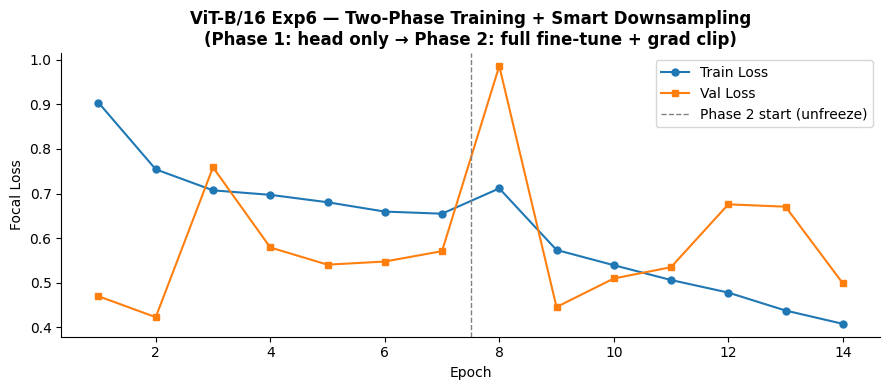

Saved → outputs/vit_b16_exp6/figures/vit_b16_exp6_loss_curve.png


In [88]:
p2_start  = len(exp6_history['phase1_train'])
all_train = exp6_history['phase1_train'] + exp6_history['phase2_train']
all_val   = exp6_history['phase1_val']   + exp6_history['phase2_val']
all_epochs = range(1, len(all_train) + 1)

print('Phase 1:')
print(f"{"Epoch":<8} {"Tr Loss":>10} {"Tr Acc":>8} {"Val Loss":>10} {"Val Acc":>8}")
print('─' * 50)
for ep, (tl, ta, vl, va) in enumerate(
    zip(exp6_history['phase1_train'], exp6_history['phase1_train_acc'],
        exp6_history['phase1_val'],   exp6_history['phase1_val_acc']), 1):
    print(f'{ep:<8} {tl:>10.4f} {ta:>8.4f} {vl:>10.4f} {va:>8.4f}')

print('\nPhase 2:')
print(f"{"Epoch":<8} {"Tr Loss":>10} {"Tr Acc":>8} {"Val Loss":>10} {"Val Acc":>8}")
print('─' * 50)
for ep, (tl, ta, vl, va) in enumerate(
    zip(exp6_history['phase2_train'], exp6_history['phase2_train_acc'],
        exp6_history['phase2_val'],   exp6_history['phase2_val_acc']), p2_start + 1):
    print(f'{ep:<8} {tl:>10.4f} {ta:>8.4f} {vl:>10.4f} {va:>8.4f}')
print()

fig, ax = plt.subplots(figsize=(9, 4))
ax.plot(all_epochs, all_train, label='Train Loss', marker='o', markersize=5)
ax.plot(all_epochs, all_val,   label='Val Loss',   marker='s', markersize=5)
if p2_start > 0:
    ax.axvline(x=p2_start + 0.5, color='gray', linestyle='--', linewidth=1, label='Phase 2 start (unfreeze)')
ax.set_title('ViT-B/16 Exp6 — Two-Phase Training + Smart Downsampling\n(Phase 1: head only → Phase 2: full fine-tune + grad clip)', fontweight='bold')
ax.set_xlabel('Epoch'); ax.set_ylabel('Focal Loss')
ax.xaxis.set_major_locator(ticker.MaxNLocator(integer=True))
ax.legend(); ax.spines[['top', 'right']].set_visible(False)
plt.tight_layout()
fig.savefig(EXP6_FIG_DIR / 'vit_b16_exp6_loss_curve.png', dpi=150, bbox_inches='tight')
plt.show()
print('Saved → outputs/vit_b16_exp6/figures/vit_b16_exp6_loss_curve.png')


In [89]:
from datetime import datetime

# ── Independent of training cell — requires Sections 1-7 + registry ──────────
_prev_model     = globals().get('model',     None)
_prev_criterion = globals().get('criterion', None)

model     = timm.create_model(MODEL_NAME, pretrained=False, num_classes=NUM_CLASSES).to(device)
criterion = nn.CrossEntropyLoss()

ckpt = torch.load(CKPT_EXP6, map_location=device, weights_only=False)
model.load_state_dict(ckpt['model_state'])
print(f'Exp6: loaded {CKPT_EXP6.name}  (epoch {ckpt["epoch"]}, val_loss={ckpt["val_loss"]:.4f})')

_, exp6_y_true, exp6_y_pred = run_epoch(test_loader, train_mode=False)

exp6_qwk      = cohen_kappa_score(exp6_y_true, exp6_y_pred, weights='quadratic')
exp6_acc      = accuracy_score(exp6_y_true, exp6_y_pred)
exp6_macro_f1 = f1_score(exp6_y_true, exp6_y_pred, average='macro')
exp6_f1_per   = f1_score(exp6_y_true, exp6_y_pred, average=None, labels=list(range(5)))

print('\nExp6 Classification Report (Test Set):')
print(classification_report(exp6_y_true, exp6_y_pred, target_names=CLASS_NAMES, digits=3))
print(f'QWK      : {exp6_qwk:.4f}')
print(f'Accuracy : {exp6_acc:.4f}')
print(f'Macro F1 : {exp6_macro_f1:.4f}')

# ── Append results to CSV log (never overwritten) ─────────────────────────────
EXP6_LOG_PATH = ROOT / 'outputs' / 'vit_b16_exp6' / 'exp6_results_log.csv'
EXP6_LOG_PATH.parent.mkdir(parents=True, exist_ok=True)

log_row = {
    'timestamp':               datetime.now().isoformat(),
    'phase1_epochs':           globals().get('EXP6_PHASE1_EPOCHS', None),
    'phase2_epochs':           globals().get('EXP6_PHASE2_EPOCHS', None),
    'phase1_lr':               globals().get('EXP6_PHASE1_LR',     None),
    'phase2_lr':               globals().get('EXP6_PHASE2_LR',     None),
    'batch_size':              globals().get('EXP6_BATCH_SIZE',     None),
    'weight_decay':            globals().get('EXP6_WEIGHT_DECAY',   None),
    'grad_clip':               globals().get('EXP6_GRAD_CLIP',      None),
    'early_stopping_patience': globals().get('EXP6_PATIENCE',       None),
    'downsample_cap':          globals().get('DOWNSAMPLE_CAP',       None),
    'focal_gamma':             2.0,
    'p1_best_epoch':           globals().get('exp6_p1_best_epoch',   None),
    'p1_best_val_loss':        globals().get('exp6_p1_best_val',     None),
    'p2_best_epoch':           globals().get('exp6_p2_best_epoch',   None),
    'p2_best_val_loss':        globals().get('exp6_p2_best_val',     None),
    'test_qwk':                round(exp6_qwk,       4),
    'test_accuracy':           round(exp6_acc,        4),
    'test_macro_f1':           round(exp6_macro_f1,   4),
    'f1_no_dr':                round(float(exp6_f1_per[0]), 4),
    'f1_mild':                 round(float(exp6_f1_per[1]), 4),
    'f1_moderate':             round(float(exp6_f1_per[2]), 4),
    'f1_severe':               round(float(exp6_f1_per[3]), 4),
    'f1_proliferative':        round(float(exp6_f1_per[4]), 4),
}

write_header = not EXP6_LOG_PATH.exists()
pd.DataFrame([log_row]).to_csv(EXP6_LOG_PATH, mode='a', header=write_header, index=False)
n_runs = sum(1 for _ in open(EXP6_LOG_PATH)) - 1
print(f'\nAppended → {EXP6_LOG_PATH}  ({n_runs} run{"s" if n_runs != 1 else ""} logged)')

if _prev_model is not None:
    model     = _prev_model
    criterion = _prev_criterion


Exp6: loaded vit_b16_exp6_best.pt  (epoch 2, val_loss=0.4452)


val:   0%|          | 0/330 [00:00<?, ?it/s]


Exp6 Classification Report (Test Set):
               precision    recall  f1-score   support

        No DR      0.865     0.681     0.762      3872
         Mild      0.108     0.434     0.173       366
     Moderate      0.509     0.399     0.447       794
       Severe      0.700     0.267     0.387       131
Proliferative      0.688     0.519     0.591       106

     accuracy                          0.608      5269
    macro avg      0.574     0.460     0.472      5269
 weighted avg      0.751     0.608     0.661      5269

QWK      : 0.5755
Accuracy : 0.6081
Macro F1 : 0.4723

Appended → /scratch/AML_G14_CW/outputs/vit_b16_exp6/exp6_results_log.csv  (1 run logged)


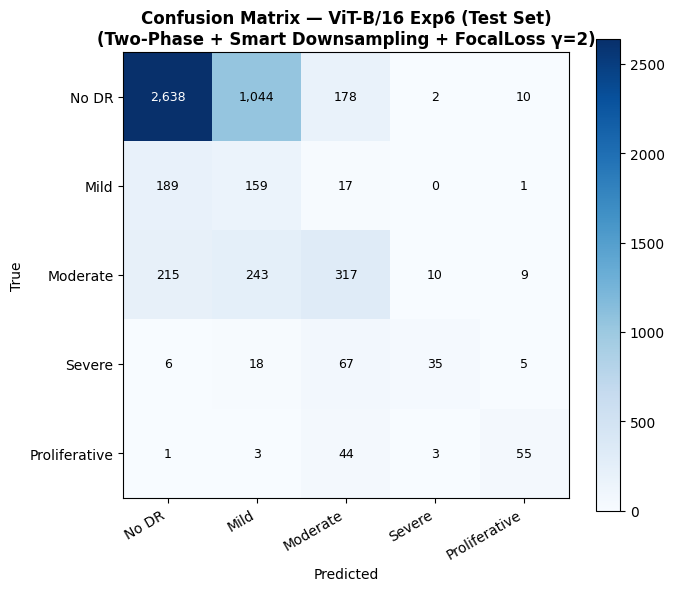

Saved → outputs/vit_b16_exp6/figures/vit_b16_exp6_confusion_matrix.png


In [90]:
cm_exp6 = confusion_matrix(exp6_y_true, exp6_y_pred)

fig, ax = plt.subplots(figsize=(7, 6))
im = ax.imshow(cm_exp6, interpolation='nearest', cmap='Blues')
fig.colorbar(im, ax=ax)
ax.set_xticks(range(NUM_CLASSES)); ax.set_xticklabels(CLASS_NAMES, rotation=30, ha='right')
ax.set_yticks(range(NUM_CLASSES)); ax.set_yticklabels(CLASS_NAMES)
ax.set_xlabel('Predicted'); ax.set_ylabel('True')
ax.set_title('Confusion Matrix — ViT-B/16 Exp6 (Test Set)\n(Two-Phase + Smart Downsampling + FocalLoss γ=2)', fontweight='bold')

thresh = cm_exp6.max() / 2
for i in range(cm_exp6.shape[0]):
    for j in range(cm_exp6.shape[1]):
        ax.text(j, i, f'{cm_exp6[i, j]:,}', ha='center', va='center', fontsize=9,
                color='white' if cm_exp6[i, j] > thresh else 'black')

plt.tight_layout()
fig.savefig(EXP6_FIG_DIR / 'vit_b16_exp6_confusion_matrix.png', dpi=150, bbox_inches='tight')
plt.show()
print('Saved → outputs/vit_b16_exp6/figures/vit_b16_exp6_confusion_matrix.png')


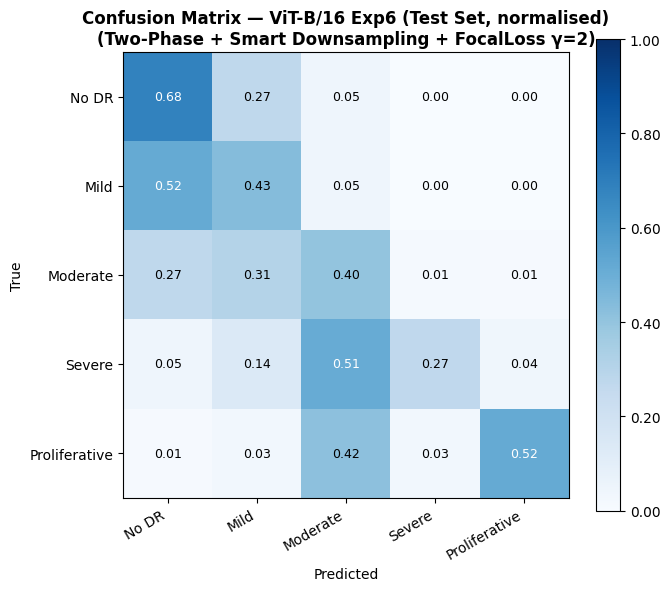

Saved → outputs/vit_b16_exp6/figures/vit_b16_exp6_confusion_matrix_normalised.png


In [91]:
cm_exp6_norm = cm_exp6.astype(float) / cm_exp6.sum(axis=1, keepdims=True)

fig, ax = plt.subplots(figsize=(7, 6))
im = ax.imshow(cm_exp6_norm, interpolation='nearest', cmap='Blues', vmin=0, vmax=1)
fig.colorbar(im, ax=ax, format='%.2f')
ax.set_xticks(range(NUM_CLASSES)); ax.set_xticklabels(CLASS_NAMES, rotation=30, ha='right')
ax.set_yticks(range(NUM_CLASSES)); ax.set_yticklabels(CLASS_NAMES)
ax.set_xlabel('Predicted'); ax.set_ylabel('True')
ax.set_title('Confusion Matrix — ViT-B/16 Exp6 (Test Set, normalised)\n(Two-Phase + Smart Downsampling + FocalLoss γ=2)', fontweight='bold')

thresh = 0.5
for i in range(cm_exp6_norm.shape[0]):
    for j in range(cm_exp6_norm.shape[1]):
        ax.text(j, i, f'{cm_exp6_norm[i, j]:.2f}', ha='center', va='center', fontsize=9,
                color='white' if cm_exp6_norm[i, j] > thresh else 'black')

plt.tight_layout()
fig.savefig(EXP6_FIG_DIR / 'vit_b16_exp6_confusion_matrix_normalised.png', dpi=150, bbox_inches='tight')
plt.show()
print('Saved → outputs/vit_b16_exp6/figures/vit_b16_exp6_confusion_matrix_normalised.png')


In [92]:
_g  = globals()
nan = float('nan')

def _v(key):
    v = _g.get(key)
    return float(v) if v is not None else nan

def _fi(key, i):
    arr = _g.get(key)
    if arr is None: return nan
    try: return float(arr[i])
    except: return nan

def fmt(v, w=8):
    return f'{"—":>{w}}' if v != v else f'{v:>{w}.4f}'

W = 96
print('=' * W)
print(f'  {"Metric":<22} {"Baseline":>10}  {"Exp1":>8}  {"Exp2":>8}  {"Exp3":>8}  {"Exp5":>8}  {"Exp6":>8}')
print('=' * W)

rows = [
    ('Test QWK',      [_v('qwk'),     _v('exp1_qwk'), _v('exp2_qwk'), _v('exp3_qwk'), _v('exp5_qwk'), exp6_qwk]),
    ('Test Accuracy', [_v('acc'),     _v('exp1_acc'), _v('exp2_acc'), _v('exp3_acc'), _v('exp5_acc'), exp6_acc]),
    ('Test Macro F1', [nan, nan, nan, nan, nan, exp6_macro_f1]),
]
for label, vals in rows:
    print(f'  {label:<22}' + ''.join(f'  {fmt(v)}' for v in vals))

print()
print('  Per-class F1:')
for i, name in enumerate(CLASS_NAMES):
    vals = [_fi('f1_per',i), _fi('exp1_f1_per',i), _fi('exp2_f1_per',i),
            _fi('exp3_f1_per',i), _fi('exp5_f1_per',i), float(exp6_f1_per[i])]
    print(f'    {name:<20}' + ''.join(f'  {fmt(v)}' for v in vals))

print('=' * W)
bqwk = _v('qwk')
if bqwk == bqwk:
    parts = []
    for k, label in [('exp1_qwk','Exp1'),('exp2_qwk','Exp2'),('exp3_qwk','Exp3'),('exp6_qwk_val','Exp6')]:
        v = _v(k) if k != 'exp6_qwk_val' else exp6_qwk
        if v == v: parts.append(f'{label}={v-bqwk:+.4f}')
    print(f'  QWK delta vs Baseline:  ' + '  '.join(parts))
print('=' * W)


  Metric                   Baseline      Exp1      Exp2      Exp3      Exp5      Exp6
  Test QWK                  0.0000    0.3480    0.5208    0.5968    0.6109    0.5755
  Test Accuracy             0.7349    0.4971    0.5511    0.6119    0.7607    0.6081
  Test Macro F1                  —         —         —         —         —    0.4723

  Per-class F1:
    No DR                   0.8472    0.6741    0.7109    0.7656    0.8704    0.7623
    Mild                    0.0000    0.1036    0.1790    0.1755    0.0000    0.1735
    Moderate                0.0000    0.2656    0.3833    0.4018    0.4936    0.4474
    Severe                  0.0000    0.2124    0.3275    0.4080    0.3505    0.3867
    Proliferative           0.0000    0.3277    0.5340    0.5578    0.6207    0.5914
  QWK delta vs Baseline:  Exp1=+0.3480  Exp2=+0.5208  Exp3=+0.5968  Exp6=+0.5755


## 17. Experiment 8 — Two-Phase Training: FocalLoss vs WRS (Ablation)

**Hypothesis:** Exp3 uses both `FocalLoss(alpha=class_weights)` and `WeightedRandomSampler` together,
creating a double-correction for class imbalance. This experiment isolates each technique to determine
which alone is more effective within the two-phase fine-tuning protocol.

| Setting | `USE_FOCAL_LOSS = True` | `USE_FOCAL_LOSS = False` |
|---|---|---|
| Imbalance correction | `FocalLoss(alpha=class_weights, γ=2)` | `WeightedRandomSampler` |
| Loss function | FocalLoss (hard-example focus) | CrossEntropyLoss |
| Batch composition | Reflects real distribution | Near-equal class frequencies |

> Reuses `exp2_train_ds` (Exp2 augmentations), `exp1_sampler` (WRS), `class_weights_t`,
> and `run_epoch_clipped` from prior sections. Training protocol identical to Exp3.


In [94]:
# ── Hyperparameter constants — edit before each run ────────────────────────────────────
USE_FOCAL_LOSS      = True   # True  → FocalLoss(alpha=class_weights, γ=2) + shuffle
                             # False → CrossEntropyLoss + WeightedRandomSampler
E8_PHASE1_EPOCHS    = 10
E8_PHASE2_EPOCHS    = 10
E8_PHASE1_LR        = 1e-5
E8_PHASE2_LR        = 1e-6
E8_BATCH_SIZE       = 16
E8_WEIGHT_DECAY     = 1e-2
E8_GRAD_CLIP        = 1.0
E8_PATIENCE         = 4

# ── Build train loader based on USE_FOCAL_LOSS ───────────────────────────────────
if USE_FOCAL_LOSS:
    # Standard shuffle — FocalLoss alpha handles class imbalance via loss scaling
    e8_train_loader = DataLoader(
        exp2_train_ds,
        batch_size=E8_BATCH_SIZE,
        shuffle=True,
        num_workers=NUM_WORKERS,
        pin_memory=True,
        drop_last=True,
        persistent_workers=NUM_WORKERS > 0,
    )
    _e8_balance = 'FocalLoss(alpha=class_weights, gamma=2)'
else:
    # WRS — balanced batch composition, plain CrossEntropyLoss
    e8_train_loader = DataLoader(
        exp2_train_ds,
        batch_size=E8_BATCH_SIZE,
        sampler=exp1_sampler,
        num_workers=NUM_WORKERS,
        pin_memory=True,
        drop_last=True,
        persistent_workers=NUM_WORKERS > 0,
    )
    _e8_balance = 'CrossEntropyLoss + WeightedRandomSampler'

print(f'USE_FOCAL_LOSS    : {USE_FOCAL_LOSS}')
print(f'Balance method    : {_e8_balance}')
print(f'Phase 1 LR/Epochs : {E8_PHASE1_LR:.0e} / {E8_PHASE1_EPOCHS}')
print(f'Phase 2 LR/Epochs : {E8_PHASE2_LR:.0e} / {E8_PHASE2_EPOCHS}')
print(f'Batch size        : {E8_BATCH_SIZE}')
print(f'Weight decay      : {E8_WEIGHT_DECAY}')
print(f'Grad clip         : {E8_GRAD_CLIP}')
print(f'Patience          : {E8_PATIENCE}')
print(f'Train loader      : {len(e8_train_loader)} batches/epoch')


USE_FOCAL_LOSS    : True
Balance method    : FocalLoss(alpha=class_weights, gamma=2)
Phase 1 LR/Epochs : 1e-05 / 10
Phase 2 LR/Epochs : 1e-06 / 10
Batch size        : 16
Weight decay      : 0.01
Grad clip         : 1.0
Patience          : 4
Train loader      : 1536 batches/epoch


In [ ]:
set_seed(SEED)
exp8_model  = timm.create_model(MODEL_NAME, pretrained=True, num_classes=NUM_CLASSES).to(device)
exp8_scaler = torch.amp.GradScaler('cuda', enabled=use_amp)

if USE_FOCAL_LOSS:
    exp8_criterion = FocalLoss(alpha=class_weights_t, gamma=2.0)
else:
    exp8_criterion = nn.CrossEntropyLoss()

EXP8_OUT_DIR  = ROOT / 'outputs' / 'vit_b16_exp8'
EXP8_CKPT_DIR = EXP8_OUT_DIR / 'checkpoints'
EXP8_FIG_DIR  = EXP8_OUT_DIR / 'figures'
for d in (EXP8_CKPT_DIR, EXP8_FIG_DIR):
    d.mkdir(parents=True, exist_ok=True)

EXP8_PHASE1_CKPT = EXP8_CKPT_DIR / 'vit_b16_exp8_phase1_best.pt'
EXP8_CKPT        = EXP8_CKPT_DIR / 'vit_b16_exp8_best.pt'

print(f'Criterion  : {exp8_criterion}')
print(f'Checkpoint → {EXP8_CKPT_DIR}')


In [ ]:
# ── Freeze backbone ──────────────────────────────────────────────────────────────
for name, param in exp8_model.named_parameters():
    if 'head' not in name:
        param.requires_grad = False

trainable_p1 = sum(p.numel() for p in exp8_model.parameters() if p.requires_grad)
print(f'Phase 1: {trainable_p1:,} trainable parameters (head only)\n')

_e8_prev_model     = globals().get('model',     None)
_e8_prev_criterion = globals().get('criterion', None)
_e8_prev_optimizer = globals().get('optimizer', None)
_e8_prev_scaler    = globals().get('scaler',    None)

model     = exp8_model
criterion = exp8_criterion
scaler    = exp8_scaler
optimizer = torch.optim.AdamW(
    filter(lambda p: p.requires_grad, model.parameters()),
    lr=E8_PHASE1_LR, weight_decay=E8_WEIGHT_DECAY,
)
scheduler_p1 = torch.optim.lr_scheduler.CosineAnnealingLR(optimizer, T_max=E8_PHASE1_EPOCHS)

exp8_history = {
    'phase1_train': [], 'phase1_val': [], 'phase1_train_acc': [], 'phase1_val_acc': [],
    'phase2_train': [], 'phase2_val': [], 'phase2_train_acc': [], 'phase2_val_acc': [],
}
e8_p1_best_val   = float('inf')
e8_p1_best_epoch = 0
e8_p1_patience   = E8_PATIENCE

print(f"{'Epoch':<8} {'Tr Loss':>10} {'Tr Acc':>8} {'Val Loss':>10} {'Val Acc':>8}")
print('─' * 50)

for epoch in range(1, E8_PHASE1_EPOCHS + 1):
    tr_loss, tr_labels, tr_preds = run_epoch_clipped(e8_train_loader, train_mode=True,  grad_clip=0.0)
    vl_loss, vl_labels, vl_preds = run_epoch_clipped(val_loader,       train_mode=False)
    scheduler_p1.step()

    tr_acc = accuracy_score(tr_labels, tr_preds)
    vl_acc = accuracy_score(vl_labels, vl_preds)
    exp8_history['phase1_train'].append(tr_loss)
    exp8_history['phase1_val'].append(vl_loss)
    exp8_history['phase1_train_acc'].append(tr_acc)
    exp8_history['phase1_val_acc'].append(vl_acc)

    marker = ''
    if vl_loss < e8_p1_best_val:
        e8_p1_best_val   = vl_loss
        e8_p1_best_epoch = epoch
        e8_p1_patience   = E8_PATIENCE
        torch.save({'epoch': epoch, 'model_state': model.state_dict(),
                    'val_loss': vl_loss}, EXP8_PHASE1_CKPT)
        marker = '  ← best'
    else:
        e8_p1_patience -= 1

    print(f'{epoch:<8} {tr_loss:>10.4f} {tr_acc:>8.4f} {vl_loss:>10.4f} {vl_acc:>8.4f}{marker}')

    if e8_p1_patience == 0:
        print(f'\nEarly stopping at epoch {epoch}.')
        break

print(f'\nPhase 1 complete. Best val loss: {e8_p1_best_val:.4f}  (epoch {e8_p1_best_epoch})')


In [ ]:
# ── Unfreeze all parameters ───────────────────────────────────────────────────────
for param in exp8_model.parameters():
    param.requires_grad = True

trainable_p2 = sum(p.numel() for p in exp8_model.parameters() if p.requires_grad)
print(f'Phase 2: {trainable_p2:,} trainable parameters (all layers)\n')

ckpt_p1 = torch.load(EXP8_PHASE1_CKPT, map_location=device, weights_only=False)
model.load_state_dict(ckpt_p1['model_state'])
print(f'Loaded Phase 1 best (epoch {ckpt_p1["epoch"]}, val_loss={ckpt_p1["val_loss"]:.4f})')

optimizer    = torch.optim.AdamW(model.parameters(), lr=E8_PHASE2_LR, weight_decay=E8_WEIGHT_DECAY)
scheduler_p2 = torch.optim.lr_scheduler.CosineAnnealingLR(optimizer, T_max=E8_PHASE2_EPOCHS)

e8_p2_best_val   = float('inf')
e8_p2_best_epoch = 0
e8_p2_patience   = E8_PATIENCE

print(f"\n{'Epoch':<8} {'Tr Loss':>10} {'Tr Acc':>8} {'Val Loss':>10} {'Val Acc':>8}")
print('─' * 50)

for epoch in range(1, E8_PHASE2_EPOCHS + 1):
    tr_loss, tr_labels, tr_preds = run_epoch_clipped(e8_train_loader, train_mode=True,  grad_clip=E8_GRAD_CLIP)
    vl_loss, vl_labels, vl_preds = run_epoch_clipped(val_loader,       train_mode=False)
    scheduler_p2.step()

    tr_acc = accuracy_score(tr_labels, tr_preds)
    vl_acc = accuracy_score(vl_labels, vl_preds)
    exp8_history['phase2_train'].append(tr_loss)
    exp8_history['phase2_val'].append(vl_loss)
    exp8_history['phase2_train_acc'].append(tr_acc)
    exp8_history['phase2_val_acc'].append(vl_acc)

    marker = ''
    if vl_loss < e8_p2_best_val:
        e8_p2_best_val   = vl_loss
        e8_p2_best_epoch = epoch
        e8_p2_patience   = E8_PATIENCE
        torch.save({'epoch': epoch, 'model_state': model.state_dict(),
                    'val_loss': vl_loss}, EXP8_CKPT)
        marker = '  ← best'
    else:
        e8_p2_patience -= 1

    print(f'{epoch:<8} {tr_loss:>10.4f} {tr_acc:>8.4f} {vl_loss:>10.4f} {vl_acc:>8.4f}{marker}')

    if e8_p2_patience == 0:
        print(f'\nEarly stopping at epoch {epoch}.')
        break

print(f'\nPhase 2 complete. Best val loss: {e8_p2_best_val:.4f}  (epoch {e8_p2_best_epoch})')
print(f'Checkpoint → {EXP8_CKPT}')

if _e8_prev_model is not None:
    model, criterion, optimizer, scaler = (
        _e8_prev_model, _e8_prev_criterion,
        _e8_prev_optimizer, _e8_prev_scaler,
    )


In [ ]:
p2_start  = len(exp8_history['phase1_train'])
all_train = exp8_history['phase1_train'] + exp8_history['phase2_train']
all_val   = exp8_history['phase1_val']   + exp8_history['phase2_val']
epochs_e8 = range(1, len(all_train) + 1)

fig, ax = plt.subplots(figsize=(9, 4))
ax.plot(epochs_e8, all_train, label='Train Loss', marker='o', markersize=4)
ax.plot(epochs_e8, all_val,   label='Val Loss',   marker='s', markersize=4)
if 0 < p2_start < len(all_train):
    ax.axvline(x=p2_start + 0.5, color='gray', linestyle='--', alpha=0.7, label='Phase 1 → Phase 2')
_title_m = 'FocalLoss(alpha=class_weights, γ=2) + Shuffle' if USE_FOCAL_LOSS else 'CrossEntropyLoss + WRS'
ax.set_title(f'ViT-B/16 Exp8 — Train vs Validation Loss\n({_title_m})', fontweight='bold')
ax.set_xlabel('Epoch')
ax.set_ylabel('Loss')
ax.xaxis.set_major_locator(ticker.MaxNLocator(integer=True))
ax.legend()
ax.spines[['top', 'right']].set_visible(False)
plt.tight_layout()
fig.savefig(EXP8_FIG_DIR / 'vit_b16_exp8_loss_curve.png', dpi=150, bbox_inches='tight')
plt.show()
print(f'Saved → outputs/vit_b16_exp8/figures/vit_b16_exp8_loss_curve.png')


In [ ]:
from datetime import datetime

# ── Independent of training — requires Sections 1-7 + registry ─────────────────────
_prev_model     = globals().get('model',     None)
_prev_criterion = globals().get('criterion', None)

_e8_eval_ckpt = ROOT / 'outputs' / 'vit_b16_exp8' / 'checkpoints' / 'vit_b16_exp8_best.pt'
model     = timm.create_model(MODEL_NAME, pretrained=False, num_classes=NUM_CLASSES).to(device)
criterion = nn.CrossEntropyLoss()
ckpt      = torch.load(_e8_eval_ckpt, map_location=device, weights_only=False)
model.load_state_dict(ckpt['model_state'])
print(f'Exp8: loaded {_e8_eval_ckpt.name}  (epoch {ckpt["epoch"]}, val_loss={ckpt["val_loss"]:.4f})')

_, exp8_y_true, exp8_y_pred = run_epoch(test_loader, train_mode=False)

exp8_qwk      = cohen_kappa_score(exp8_y_true, exp8_y_pred, weights='quadratic')
exp8_acc      = accuracy_score(exp8_y_true, exp8_y_pred)
exp8_macro_f1 = f1_score(exp8_y_true, exp8_y_pred, average='macro')
exp8_f1_per   = f1_score(exp8_y_true, exp8_y_pred, average=None, labels=list(range(5)))

print('\nExp8 Classification Report (Test Set):')
print(classification_report(exp8_y_true, exp8_y_pred, target_names=CLASS_NAMES, digits=3))
print(f'QWK      : {exp8_qwk:.4f}')
print(f'Accuracy : {exp8_acc:.4f}')
print(f'Macro F1 : {exp8_macro_f1:.4f}')

# ── Append to CSV log (never overwritten) ─────────────────────────────────────────────
EXP8_LOG_PATH = ROOT / 'outputs' / 'vit_b16_exp8' / 'exp8_results_log.csv'
EXP8_LOG_PATH.parent.mkdir(parents=True, exist_ok=True)

_use_fl  = globals().get('USE_FOCAL_LOSS', None)
_bmethod = ('FocalLoss(alpha=class_weights,gamma=2)' if _use_fl is True
             else 'CrossEntropyLoss+WRS' if _use_fl is False else 'unknown')

log_row = {
    'timestamp':               datetime.now().isoformat(),
    'use_focal_loss':          _use_fl,
    'balance_method':          _bmethod,
    'phase1_epochs':           globals().get('E8_PHASE1_EPOCHS', None),
    'phase2_epochs':           globals().get('E8_PHASE2_EPOCHS', None),
    'phase1_lr':               globals().get('E8_PHASE1_LR',     None),
    'phase2_lr':               globals().get('E8_PHASE2_LR',     None),
    'batch_size':              globals().get('E8_BATCH_SIZE',    None),
    'weight_decay':            globals().get('E8_WEIGHT_DECAY',  None),
    'grad_clip':               globals().get('E8_GRAD_CLIP',     None),
    'early_stopping_patience': globals().get('E8_PATIENCE',      None),
    'p1_best_epoch':           globals().get('e8_p1_best_epoch', None),
    'p1_best_val_loss':        globals().get('e8_p1_best_val',   None),
    'p2_best_epoch':           globals().get('e8_p2_best_epoch', None),
    'p2_best_val_loss':        globals().get('e8_p2_best_val',   None),
    'test_qwk':                round(exp8_qwk, 4),
    'test_accuracy':           round(exp8_acc, 4),
    'test_macro_f1':           round(exp8_macro_f1, 4),
    'f1_no_dr':                round(float(exp8_f1_per[0]), 4),
    'f1_mild':                 round(float(exp8_f1_per[1]), 4),
    'f1_moderate':             round(float(exp8_f1_per[2]), 4),
    'f1_severe':               round(float(exp8_f1_per[3]), 4),
    'f1_proliferative':        round(float(exp8_f1_per[4]), 4),
}
write_header = not EXP8_LOG_PATH.exists()
pd.DataFrame([log_row]).to_csv(EXP8_LOG_PATH, mode='a', header=write_header, index=False)
print(f'\nLogged → {EXP8_LOG_PATH}')

if _prev_model is not None:
    model = _prev_model; criterion = _prev_criterion


In [ ]:
cm_exp8 = confusion_matrix(exp8_y_true, exp8_y_pred)

fig, ax = plt.subplots(figsize=(7, 6))
im = ax.imshow(cm_exp8, interpolation='nearest', cmap='Blues')
fig.colorbar(im, ax=ax)
ax.set_xticks(range(NUM_CLASSES)); ax.set_xticklabels(CLASS_NAMES, rotation=30, ha='right')
ax.set_yticks(range(NUM_CLASSES)); ax.set_yticklabels(CLASS_NAMES)
ax.set_xlabel('Predicted'); ax.set_ylabel('True')
ax.set_title('Confusion Matrix — ViT-B/16 Exp8 (Test Set)\n(Two-Phase + FocalLoss or WRS)', fontweight='bold')
thresh = cm_exp8.max() / 2
for i in range(cm_exp8.shape[0]):
    for j in range(cm_exp8.shape[1]):
        ax.text(j, i, f'{cm_exp8[i, j]:,}', ha='center', va='center', fontsize=9,
                color='white' if cm_exp8[i, j] > thresh else 'black')
plt.tight_layout()
fig.savefig(EXP8_FIG_DIR / 'vit_b16_exp8_confusion_matrix.png', dpi=150, bbox_inches='tight')
plt.show()
print(f'Saved → outputs/vit_b16_exp8/figures/vit_b16_exp8_confusion_matrix.png')


In [ ]:
cm_exp8_norm = cm_exp8.astype(float) / cm_exp8.sum(axis=1, keepdims=True)

fig, ax = plt.subplots(figsize=(7, 6))
im = ax.imshow(cm_exp8_norm, interpolation='nearest', cmap='Blues', vmin=0, vmax=1)
fig.colorbar(im, ax=ax, format='%.2f')
ax.set_xticks(range(NUM_CLASSES)); ax.set_xticklabels(CLASS_NAMES, rotation=30, ha='right')
ax.set_yticks(range(NUM_CLASSES)); ax.set_yticklabels(CLASS_NAMES)
ax.set_xlabel('Predicted'); ax.set_ylabel('True')
ax.set_title('Confusion Matrix — ViT-B/16 Exp8 (Test Set, normalised)\n(Two-Phase + FocalLoss or WRS)', fontweight='bold')
thresh = 0.5
for i in range(cm_exp8_norm.shape[0]):
    for j in range(cm_exp8_norm.shape[1]):
        ax.text(j, i, f'{cm_exp8_norm[i, j]:.2f}', ha='center', va='center', fontsize=9,
                color='white' if cm_exp8_norm[i, j] > thresh else 'black')
plt.tight_layout()
fig.savefig(EXP8_FIG_DIR / 'vit_b16_exp8_confusion_matrix_norm.png', dpi=150, bbox_inches='tight')
plt.show()
print(f'Saved → outputs/vit_b16_exp8/figures/vit_b16_exp8_confusion_matrix_norm.png')


In [ ]:
_g  = globals()
nan = float('nan')

def _v(key):
    v = _g.get(key)
    return float(v) if v is not None else nan

def _fi(key, i):
    arr = _g.get(key)
    if arr is None: return nan
    try: return float(arr[i])
    except: return nan

def fmt(v, w=8):
    return f'{"—":>{w}}' if v != v else f'{v:>{w}.4f}'

W = 106
print('=' * W)
print(f'  {"Metric":<22} {"Baseline":>10}  {"Exp1":>8}  {"Exp2":>8}  {"Exp3":>8}  {"Exp5":>8}  {"Exp6":>8}  {"Exp8":>8}')
print('=' * W)

rows = [
    ('Test QWK',      [_v('qwk'),     _v('exp1_qwk'), _v('exp2_qwk'), _v('exp3_qwk'),
                       _v('exp5_qwk'), _v('exp6_qwk'), exp8_qwk]),
    ('Test Accuracy', [_v('acc'),     _v('exp1_acc'), _v('exp2_acc'), _v('exp3_acc'),
                       _v('exp5_acc'), _v('exp6_acc'), exp8_acc]),
    ('Test Macro F1', [nan, nan, nan, nan, nan, _v('exp6_macro_f1'), exp8_macro_f1]),
]
for label, vals in rows:
    print(f'  {label:<22}' + ''.join(f'  {fmt(v)}' for v in vals))

print()
print('  Per-class F1:')
for i, name in enumerate(CLASS_NAMES):
    vals = [_fi('f1_per', i), _fi('exp1_f1_per', i), _fi('exp2_f1_per', i),
            _fi('exp3_f1_per', i), _fi('exp5_f1_per', i), _fi('exp6_f1_per', i),
            float(exp8_f1_per[i])]
    print(f'    {name:<20}' + ''.join(f'  {fmt(v)}' for v in vals))

print('=' * W)
bqwk = _v('qwk')
if bqwk == bqwk:
    parts = []
    for k, lbl in [('exp1_qwk','Exp1'),('exp2_qwk','Exp2'),('exp3_qwk','Exp3'),
                   ('exp5_qwk','Exp5'),('exp6_qwk','Exp6')]:
        v = _v(k)
        if v == v: parts.append(f'{lbl}={v - bqwk:+.4f}')
    parts.append(f'Exp8={exp8_qwk - bqwk:+.4f}')
    print(f'  QWK delta vs Baseline:  ' + '  '.join(parts))

_use_fl = globals().get('USE_FOCAL_LOSS', None)
if _use_fl is not None:
    _m = 'FocalLoss(alpha=class_weights, gamma=2)' if _use_fl else 'CrossEntropyLoss + WRS'
    print(f'  Exp8 balance method: {_m}')
print()
